# Reviewer checks: full test set, training objectives, layer pairs (Gemma-2 9B → 2B (graft L20 ← L34))

The paper's basic first-token stitch (GitHub EXP2/EXP3, seed 0), re-run and checked against GitHub, then
three checks the reviewers asked for:

| Part | Reviewer point | What it does |
|---|---|---|
| R1 | (baseline) | The paper's task map, alignment (recon) map and a CONST null; GitHub sanity checks print PASS / WARN / CHECK. |
| R2 | Q3 / W4: the full test set | Every eval problem (not only those the donor gets right), split by whether the donor and the recipient get it right. In each group: native vs stitched accuracy (first token and full answer), problems lost (native right, stitched wrong) and gained, and how often the stitched answer equals the donor's answer (including the donor's wrong answers). |
| R3 | Q1 / W2: the training objective | Maps trained with other objectives on the same data: alignment (MSE to the recipient's own state), first-token CE + alignment, continuation CE on every answer token, and distillation from the donor's own next-token distribution along the answer. Each is scored on the paper's bin for first-token and full-answer conferral, teacher-forced accuracy at each answer digit, a shuffled-donor control, and against the paper's task map. |
| R4 | Q2 / W3: the layer pair | Every donor layer x recipient layer pair in a grid (the paper's pair included): first-token and full-answer conferral, the alignment map, a shuffled-donor control and a CONST null for each. |
| R5 | Q4: presentation | One figure with the key results side by side. |

**Running it.** Fresh pod with a 48 GB card (same as the other notebooks). Run cell 1, **restart the kernel**,
paste your HF token in the login cell for Gemma (clear it before sharing), then run all. About 1.5 h for Gemma
and 40 min for Qwen; R4 is about half of that and runs last. The JSON (`reviewer_checks_<pair>.json`) is saved
after every part; plots go to `reviewer_checks_<pair>_plots/`. Trained maps are cached, so a kernel restart
re-runs from the top without retraining.

In [2]:
# === CELL 1: install into THIS kernel's Python (run once, then RESTART THE KERNEL) ===
# Installs with the kernel's own interpreter (sys.executable). On vast.ai (and some other hosts) the `pip` on the
# PATH belongs to a different Python than the notebook kernel, so `!pip install` leaves the kernel without
# numpy / torch. Pins = the Emergence notebooks' (transformers 4.46.3). torch: the image's build is kept if the
# kernel has one; otherwise one matched to the GPU is installed (GitHub's runs used torch 2.4.1 + CUDA 12.4;
# Blackwell cards, compute capability 12.x such as RTX 5090 / RTX PRO 6000, need a CUDA 12.8 build).
import sys, subprocess, shutil, importlib.util
print("kernel python:", sys.executable)
def _pip(*args):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args])
    if r.returncode != 0:                      # a bare venv without pip: bootstrap it once and retry
        subprocess.run([sys.executable, "-m", "ensurepip", "--upgrade"])
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)
def _have(mod): return importlib.util.find_spec(mod) is not None
_cap = None
if shutil.which("nvidia-smi"):
    _out = subprocess.run(["nvidia-smi", "--query-gpu=name,compute_cap", "--format=csv,noheader"],
                          capture_output=True, text=True).stdout.strip().splitlines()
    if _out:
        print("GPU:", _out[0]); _cap = float(_out[0].split(",")[-1])
if not _have("torch"):
    print("no torch in this kernel: installing one for compute capability", _cap)
    if _cap is not None and _cap >= 12:
        _pip("torch", "--index-url", "https://download.pytorch.org/whl/cu128")
    else:
        _pip("torch==2.4.1", "--index-url", "https://download.pytorch.org/whl/cu124")
_pip("transformers==4.46.3", "accelerate", "matplotlib", "huggingface_hub", "hf_transfer",
     *([] if _have("numpy") else ["numpy<2"]))
# torchvision / torchaudio from the image can clash with the torch above when transformers imports them
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchvision", "torchaudio"])
print("deps installed into", sys.executable, "-> RESTART THE KERNEL now, then continue from CELL 2")

kernel python: /usr/bin/python
GPU: NVIDIA L40S, 8.9



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


deps installed into /usr/bin/python -> RESTART THE KERNEL now, then continue from CELL 2


In [3]:
# === CELL 2: imports + RUN CONFIG ===
import os
os.environ.setdefault("HF_HUB_ENABLE_HF_TRANSFER", "1")
import json, math, random, time, gc, re, collections
from fractions import Fraction
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
_GPU = (torch.cuda.get_device_name(0), list(torch.cuda.get_device_capability(0))) if torch.cuda.is_available() else ("cpu", None)
if torch.cuda.is_available():                  # does this torch build carry kernels for this GPU generation?
    _majors = {int(m_.group(1)[:-1]) for a_ in torch.cuda.get_arch_list() for m_ in [re.match(r"sm_(\d{2,3})", a_)] if m_}
    assert not _majors or _GPU[1][0] in _majors, (
        f"this torch ({torch.__version__}) has no kernels for {_GPU[0]} (compute capability {_GPU[1]}). In a cell run:\n"
        f"  import sys, subprocess; subprocess.run([sys.executable, '-m', 'pip', 'install', '--upgrade', 'torch', "
        f"'--index-url', 'https://download.pytorch.org/whl/cu128'])\nthen RESTART THE KERNEL and run from CELL 2.")
print(f"torch {torch.__version__} | transformers {transformers.__version__} (want 4.46.3) | {_GPU[0]} cap {_GPU[1]} "
      f"(GitHub's run: torch 2.4.1+cu124, cap (8, 9))")

PAIR = "gemma"            # "gemma" or "qwen"
SMOKE_TEST = False             # True = plumbing check with tiny sizes; numbers meaningless

_PAIRS = {   # = MODEL_2B / MODEL_9B / SINGLE_PAIR (recipient layer, donor layer) in the Emergence notebooks
    "gemma": dict(MODEL_R="google/gemma-2-2b", MODEL_D="google/gemma-2-9b", L_R=20, L_D=34),
    "qwen":  dict(MODEL_R="Qwen/Qwen2.5-0.5B", MODEL_D="Qwen/Qwen2.5-7B", L_R=17, L_D=23),
}
MODEL_R, MODEL_D, L_R, L_D = (_PAIRS[PAIR][x] for x in ("MODEL_R", "MODEL_D", "L_R", "L_D"))

# --- Emergence S4 recipe, unchanged ---
N_TRAIN, N_EVAL = 3000, 2000
ARITH_BATCH = BATCH = 16          # recipient batches: states, training, scoring
COLLECT_BATCH = 8                 # donor batches (= collect_states_multi)
TASK_EPOCHS, RIDGE_LAMBDA = 6, 1e3
K_LIST = [2, 3]                   # digit 2 (= S4) and digit 3 (new)

# --- what to run (cut from the bottom of this list first if time is short) ---
RUN_EXTRA_SEED = True             # PREFILL and MID_PRED with a second training order (used in the primary test)
RUN_MLP_MAP = True                # nonlinear map: ridge-initialised linear map + zero-initialised MLP residual
RUN_SWAPS = True                  # Part 4 (and its partner extraction in CELL 8)
RUN_ERASURE = True                # Part 5
RUN_BOTTLENECK = True             # Part 6
RUN_CONTINUATION = True           # Part 7 (same-bin completion: does the digit-k graft help digit k+1?)
RUN_FIRST_TOKEN = True            # Part 0: the paper's basic first-token stitch (EXP2/EXP3), with loss curves
FT_SEEDS = [0]                    # first-token task-map seeds (the paper trained 5; seed 0 is the one it scores)
RUN_LONG = True                   # continue PREFILL, MID_PRED, CONST, PREFIX (and the first-token map) to LONG_EPOCHS
LONG_EPOCHS = 20                  # the 6-epoch snapshot of the same run is the map every other part uses
FREE_DONOR = True                 # drop the donor from the GPU once every donor state is extracted
CACHE_MAPS = True                 # trained maps saved with a fingerprint; a re-run loads matching ones

# --- test settings ---
SESOI = 0.05                      # smallest effect of interest (conferral points)
WRITER_LAMBDA = 1.0               # ridge lambda for code-fed writers (one-hot / softmax inputs)
MLP_MAP_HIDDEN = 1024
SVD_RANKS = [1, 2, 4, 8, 16, 32, 64, 128, 256]       # + 0 and full
INLP_RANKS = [10, 20, 40, 80, 160]                    # 10 directions per round (a 10-way digit probe)
SHUF_SEEDS = [0, 1, 2]
TRAIN_SAMPLE = 800                # training-bin problems scored per SVD rank
MONITOR_SAMPLE = 600              # training-bin problems scored after every epoch
PROBE_MLP_STEPS = 800             # = probe_mlp (Followup3_MLPprobe)
N_FOLDS = 5                       # cross-fitted bottleneck readers
SWAP_SEED, N_CAND, MIN_GAP = 1234, 3, 2               # partner swaps: up to N_CAND tries, digit-k gap >= MIN_GAP
BN_SEED = 0
LONG_MAPS = ("PREFILL", "MID_PRED", "CONST", "PREFIX")
MAX_NEW_ARITH = 8                 # = Emergence: greedy tokens for full-answer generation (Part 0)
MIN_CONT_N = 30                   # Part 7 needs at least this many solvable-bin problems
CONT_MAX_NEW = 6                  # greedy tokens generated after digit k-1 (answers have <= 4 digits)
BOOT_B = 4000
CODE_VERSION = "reviewer-v1"
if SMOKE_TEST:
    N_TRAIN, N_EVAL, TASK_EPOCHS = 300, 250, 2
    SVD_RANKS, INLP_RANKS, SHUF_SEEDS = [1, 4, 16], [10, 20], [0, 1]
    TRAIN_SAMPLE, MONITOR_SAMPLE, PROBE_MLP_STEPS, MLP_MAP_HIDDEN, N_CAND, BOOT_B = 80, 60, 60, 64, 2, 500
    MIN_CONT_N = 5
    LONG_EPOCHS = TASK_EPOCHS + 2
assert SHUF_SEEDS and INLP_RANKS and SVD_RANKS

TAG = f"reviewer_checks_{PAIR}" + ("_SMOKE" if SMOKE_TEST else "")
OUT_JSON = TAG + ".json"
CACHE_DIR = f"{TAG}_maps_{CODE_VERSION}"
PLOT_DIR = f"{TAG}_plots"
os.makedirs(CACHE_DIR, exist_ok=True); os.makedirs(PLOT_DIR, exist_ok=True)
SANITY = {}
RESULTS = {"_config": dict(pair=PAIR, donor=MODEL_D, recipient=MODEL_R, L_R=L_R, L_D=L_D, n_train=N_TRAIN,
                           n_eval=N_EVAL, epochs=TASK_EPOCHS, k_list=K_LIST, smoke=SMOKE_TEST, sesoi=SESOI,
                           mlp_map_hidden=MLP_MAP_HIDDEN, min_gap=MIN_GAP, code_version=CODE_VERSION,
                           long_epochs=LONG_EPOCHS if RUN_LONG else None, ft_seeds=FT_SEEDS,
                           torch=torch.__version__, transformers=transformers.__version__,
                           gpu=_GPU[0], cuda_capability=_GPU[1]),
           "SANITY": SANITY}
PER_ITEM = {}
def save(tag=""):
    with open(OUT_JSON, "w") as f:
        json.dump({**RESULTS, "per_item": PER_ITEM, "_last": tag}, f, indent=1, default=str)
    print(f"  [saved {OUT_JSON}{' after ' + tag if tag else ''}]")

# --- what the GitHub Emergence runs got (sanity targets) ---
_REF = {
    "gemma": dict(n_donor_solved=1693,
                  ft=dict(n_unsolv=632, task_first=0.886, recon_first=0.191, native_full=0.003, recon_full=0.034,
                          task_full=0.127, final_batch_ce=0.008, task_solv_first=0.951, recon_cos_recon=0.981,
                          recon_cos_task=0.219, shuffle_first=0.102),
                  s4=dict(n_eval=1693, n_fail=1233, A=0.234, B=0.515, C=0.999, C_shuffle=0.102),
                  s2_n=1384, s2={34: dict(prefill_d2=0.16, diag_d2=0.182, diag_d3=0.585),
                                 37: dict(prefill_d2=0.22, diag_d2=0.364, diag_d3=0.71),
                                 41: dict(prefill_d2=0.24, diag_d2=0.455, diag_d3=0.73)}),
    "qwen": dict(n_donor_solved=1681,
                 ft=dict(n_unsolv=568, task_first=0.794, recon_first=0.134, native_full=0.000, recon_full=0.005,
                         task_full=0.038, final_batch_ce=0.094, task_solv_first=0.868, recon_cos_recon=0.991,
                         recon_cos_task=0.071, shuffle_first=0.178),
                 s4=dict(n_eval=1681, n_fail=1240, A=0.149, B=0.436, C=0.998, C_shuffle=0.106),
                 s2_n=1379, s2={23: dict(prefill_d2=0.157, diag_d2=0.171, diag_d3=0.335),
                                25: dict(prefill_d2=0.204, diag_d2=0.233, diag_d3=0.546),
                                27: dict(prefill_d2=0.228, diag_d2=0.394, diag_d3=0.583)}),
}
REF = _REF[PAIR]
def check(name, got, want, tol, warn=None):
    """PASS within tol; WARN within warn (a bf16 argmax tie or a different GPU can move a few items); CHECK
    beyond. SMOKE runs record SKIP (tiny data, nothing to compare)."""
    if SMOKE_TEST: st = "SKIP"
    else:
        d = abs(got - want)
        st = "PASS" if d <= tol else ("WARN" if warn is not None and d <= warn else "CHECK")
    SANITY[name] = {"github": want, "this_run": got, "status": st}
    print(f"  {st:5s} {name:52s} github {want}   this run {got}")
print("PAIR =", PAIR, "| SMOKE_TEST =", SMOKE_TEST, "| device", DEVICE)

torch 2.4.1+cu124 | transformers 4.46.3 (want 4.46.3) | NVIDIA L40S cap [8, 9] (GitHub's run: torch 2.4.1+cu124, cap (8, 9))
PAIR = gemma | SMOKE_TEST = False | device cuda


In [4]:
# === CELL R-CONFIG: what the reviewer checks run (after CELL 2) ===
_GRID = {"gemma": dict(D=[14, 24, 34, 40], R=[8, 14, 20, 23]),     # donor has 42 layers, recipient 26
         "qwen":  dict(D=[9, 16, 23, 26], R=[6, 12, 17, 21])}       # donor has 28 layers, recipient 24
GRID_D, GRID_R = list(_GRID[PAIR]["D"]), list(_GRID[PAIR]["R"])     # must include the paper's pair (L_D, L_R)
# 5 x 5 instead (about 1.6x R4's time): gemma D=[14, 21, 28, 34, 40], R=[8, 13, 17, 20, 23];
#                                       qwen  D=[9, 14, 19, 23, 26],  R=[6, 10, 14, 17, 21]
GRID_FULL_ANSWER = True        # full-answer generation for every layer pair (about a third of R4's time)
ALIGN_WEIGHTS = [0.1, 1.0, 10.0]   # first-token CE + w x (MSE to the recipient's own state / its variance)
KD_TOPK = 64                   # how much of the donor's next-token distribution the distillation objective keeps
RUN_FULLSET, RUN_OBJECTIVES, RUN_GRID = True, True, True
if SMOKE_TEST: KD_TOPK = 16
RESULTS["_config"].update(align_weights=ALIGN_WEIGHTS, kd_topk=KD_TOPK, grid_full_answer=GRID_FULL_ANSWER)
print("grid (before model load):", GRID_D, "x", GRID_R)

grid (before model load): [14, 24, 34, 40] x [8, 14, 20, 23]


In [ ]:
# === CELL 3: Hugging Face login (Gemma is gated; Qwen is not) ===
from huggingface_hub import login
_tok = os.environ.get("") or ""   # paste, run, then clear before sharing
if PAIR == "gemma" or not _tok.startswith("hf_PASTE"):
    login(_tok); print("logged in")
else:
    print("no token set; Qwen is not gated, continuing")
del _tok

logged in


In [6]:
# === CELL 4: statistics helpers ===
def wilson(k, n, z=1.96):
    if n == 0: return (float("nan"),) * 3
    p = k / n; d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = (z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / d
    return p, max(0.0, c - h), min(1.0, c + h)
def wilson_bools(b, z=1.96):
    b = np.asarray(b, bool); return wilson(int(b.sum()), int(b.size), z)
def fmt(tr): p, lo, hi = tr; return f"{p:.3f} [{lo:.3f}, {hi:.3f}]"
def rate(v):
    v = [x for x in v if x is not None and not (isinstance(x, float) and math.isnan(x))]
    return round(float(np.mean(v)), 4) if len(v) else None
def mcnemar_exact(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01 = int((~a & b).sum()); n10 = int((a & ~b).sum()); n = n01 + n10
    if n == 0: return dict(n01=0, n10=0, p=1.0)
    k = min(n01, n10); tot = Fraction(0)
    for i in range(0, k + 1): tot += Fraction(math.comb(n, i))
    return dict(n01=n01, n10=n10, p=min(1.0, float(2 * tot / Fraction(2) ** n)))
def R(ok):
    """Rate with a Wilson 95% interval."""
    ok = [bool(x) for x in ok]
    if not ok: return {"n": 0, "rate": None, "ci": None}
    return {"n": len(ok), "rate": round(float(np.mean(ok)), 4), "ci": fmt(wilson_bools(ok))}
def paired(a, b, seed=0, alpha=0.05):
    """b minus a on the same items (NaN pairs dropped): mean difference, percentile-bootstrap interval at
    level 1-alpha, two-sided bootstrap p; exact McNemar when both are 0/1."""
    a = np.asarray(a, float); b = np.asarray(b, float); keep = ~(np.isnan(a) | np.isnan(b)); a, b = a[keep], b[keep]
    d = b - a
    if len(d) == 0: return {"n": 0, "diff": None, "lo": None, "hi": None, "ci": None, "p_boot": None, "level": 1 - alpha}
    rng = np.random.default_rng(seed); m = d[rng.integers(0, len(d), (BOOT_B, len(d)))].mean(1)
    lo, hi = np.percentile(m, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p = float(min(1.0, 2 * min((m <= 0).mean(), (m >= 0).mean())))
    out = {"n": int(len(d)), "diff": round(float(d.mean()), 4), "lo": round(float(lo), 4), "hi": round(float(hi), 4),
           "ci": f"{d.mean():+.3f} [{lo:+.3f}, {hi:+.3f}]", "p_boot": round(p, 5), "level": 1 - alpha}
    if set(np.unique(a)) <= {0.0, 1.0} and set(np.unique(b)) <= {0.0, 1.0}:
        mc = mcnemar_exact(a > 0.5, b > 0.5); out.update(only_a=mc["n10"], only_b=mc["n01"], mcnemar_p=mc["p"])
    return out
def holm(pvals):
    """Holm step-down adjusted p-values for a dict name -> p."""
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out = {}; run = 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p)); out[k] = round(run, 5)
    return out
def effect_label(p, what="effect"):
    """Three-way: ABOVE (interval > 0) / BELOW (< 0) / no detectable effect, with its upper bound; 'equivalent
    to none' only when the upper bound is below SESOI."""
    if p is None or p.get("lo") is None: return "n/a"
    if p.get("only_a") == 0 and p.get("only_b") == 0:
        return f"identical on all {p['n']} items (no discordant pairs; the interval is degenerate)"
    if p["lo"] > 0: return f"ABOVE ({p['ci']})"
    if p["hi"] < 0: return f"BELOW ({p['ci']})"
    return (f"no detectable {what}: at most {p['hi']:+.3f}" +
            (f" (< SESOI {SESOI}: equivalent to none)" if p["hi"] < SESOI else f" (cannot rule out {SESOI})"))
def above(p): return p is not None and p.get("lo") is not None and p["lo"] > 0
print("stats ready")

stats ready


In [7]:
# === CELL 5: shared helpers (= Emergence CELL 5, the parts S4 uses) ===
PATCH_POS = -1
def _hid(o): return o[0] if isinstance(o, tuple) else o
def _pack(o, h): return (h,) + tuple(o[1:]) if isinstance(o, tuple) else h
def left_pad(id_list, pad_id):
    L = max(t.numel() for t in id_list)
    ids = torch.full((len(id_list), L), pad_id, dtype=torch.long)
    m = torch.zeros((len(id_list), L), dtype=torch.long)
    for i, t in enumerate(id_list):
        t = t.flatten(); ids[i, L - t.numel():] = t; m[i, L - t.numel():] = 1
    return ids, m
def fit_ridge(X9, X2, lam=RIDGE_LAMBDA):
    mu9, mu2 = X9.mean(0), X2.mean(0)
    A, B = X9 - mu9, X2 - mu2
    W = torch.linalg.solve(A.T @ A + lam * torch.eye(A.shape[1]), A.T @ B)
    return mu9, mu2, W
FEWSHOT = ("2 + 5 = 7\n6 * 3 = 18\n4 * 7 + 2 = 30\n9 * 8 = 72\n"
           "3 * 4 + 5 = 17\n40 * 20 = 800\n")
def _aprompt(expr): return f"{FEWSHOT}{expr} ="
def _aencode(tok, expr, ans):
    p = tok(_aprompt(expr)).input_ids
    f = tok(_aprompt(expr) + " " + str(ans)).input_ids
    if f[:len(p)] != p or len(f) <= len(p): return None, None
    j = len(p)
    while j < len(f) and not any(ch.isdigit() for ch in tok.decode([f[j]])): j += 1
    if j >= len(f): return None, None
    return torch.tensor(f[:j]), f[j]
def gen_arith(tok, n, rng, exclude=None):
    exclude = exclude or set(); out, seen = [], set()
    tries = 0
    while len(out) < n and tries < n * 120:
        tries += 1
        a, b, c = rng.randint(2, 40), rng.randint(2, 40), rng.randint(1, 99)
        expr, ans = f"{a} * {b} + {c}", a * b + c
        if expr in seen or expr in exclude: continue
        seen.add(expr)
        ids, tok_id = _aencode(tok, expr, ans)
        if tok_id is None: continue
        out.append(dict(expr=expr, ans=ans, ids=ids, tok=tok_id))
    return out
@torch.inference_mode()
def states_and_top(model, layers, prob_ids, batch=ARITH_BATCH):
    acc = {L: [] for L in layers}; top = []
    for i in range(0, len(prob_ids), batch):
        ids, m = left_pad(prob_ids[i:i + batch], tokenizer.pad_token_id)
        out = model(ids.to(DEVICE), attention_mask=m.to(DEVICE), output_hidden_states=True)
        for L in layers: acc[L].append(out.hidden_states[L + 1][:, -1, :].float().cpu())
        top += out.logits[:, -1, :].argmax(-1).cpu().tolist()
    return {L: torch.cat(v) for L, v in acc.items()}, top
_graft = {"vec": None}
def patch_vec_batch(_m, _i, o):
    h = _hid(o); vec = _graft["vec"]
    if vec is None or h.shape[1] <= 1 or h.shape[0] != vec.shape[0]:
        return o
    h2 = torch.cat([h[:, :-1, :], vec.to(h.dtype).unsqueeze(1)], 1)
    return _pack(o, h2)
_EXPR_RE = re.compile(r"^(\d+) \* (\d+) \+ (\d+)$")
def _ex(a, b, c): return f"{a} * {b} + {c}"
def _parse_first_int(text):
    """Arithmetic answers: the FIRST integer the model emits after '=' (= Emergence CELL 5)."""
    m = re.search(r"-?\d+", text)
    return float(m.group()) if m else None
@torch.inference_mode()
def arith_fullanswer_correct(model, layer, probs, vecs=None, batch=ARITH_BATCH):
    """= Emergence CELL 5: generate the full number, compare to gold; vecs[i] grafted at the last prompt
    position of problem i during prefill."""
    ok, handle = [], None
    if vecs is not None:
        handle = model.model.layers[layer].register_forward_hook(patch_vec_batch)
    try:
        for i in range(0, len(probs), batch):
            chunk = probs[i:i + batch]
            ids, m = left_pad([p["ids"] for p in chunk], tokenizer.pad_token_id)
            ids, m = ids.to(DEVICE), m.to(DEVICE)
            _graft["vec"] = (torch.stack(vecs[i:i + len(chunk)]).to(DEVICE) if vecs is not None else None)
            gen = model.generate(ids, attention_mask=m, max_new_tokens=MAX_NEW_ARITH,
                                 do_sample=False, pad_token_id=tokenizer.eos_token_id)
            txt = tokenizer.batch_decode(gen[:, ids.shape[1]:], skip_special_tokens=True)
            for p, t in zip(chunk, txt):
                pred = _parse_first_int(t)
                ok.append(pred is not None and abs(pred - p["ans"]) < 0.5)
    finally:
        if handle: handle.remove()
        _graft["vec"] = None
    return ok
print("helpers ready")

helpers ready


In [8]:
# === CELL 6: load both models (bf16, eager attention), assert a shared tokenizer (= Emergence CELL 6) ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_R)
tokenizer.padding_side = "left"
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
model_r = AutoModelForCausalLM.from_pretrained(MODEL_R, torch_dtype=torch.bfloat16, attn_implementation="eager",
                                               low_cpu_mem_usage=True).to(DEVICE).eval()
model_d = AutoModelForCausalLM.from_pretrained(MODEL_D, torch_dtype=torch.bfloat16, attn_implementation="eager",
                                               low_cpu_mem_usage=True).to(DEVICE).eval()
model_r.requires_grad_(False); model_d.requires_grad_(False)
with torch.inference_mode():
    _hl = model_d(tokenizer("The capital of France is", return_tensors="pt").to(DEVICE).input_ids).logits[0, -1, :]
assert not torch.isnan(_hl).any() and not torch.isinf(_hl).any(), "donor produced NaN/Inf logits"
del _hl
_t1, _t2 = AutoTokenizer.from_pretrained(MODEL_R), AutoTokenizer.from_pretrained(MODEL_D)
_probe = "3 * 12 + 7 = 43\nThe answer is 256."
assert _t1(_probe).input_ids == _t2(_probe).input_ids, "tokenizer mismatch: positions would not align"
del _t1, _t2
print("loaded:", model_r.config.num_hidden_layers, "recipient layers,", model_d.config.num_hidden_layers, "donor layers")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/818 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

... (18 outputs left out)

tokenizer.model:   0%|          | 0.00/4.24M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.5M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

loaded: 26 recipient layers, 42 donor layers


In [9]:
# === CELL 9: map machinery (S4's _train / _confer, generalised), nulls, probes ===
def apply_map(M, x, W=None):
    """graft = (x - mu) @ W + b  [+ MLP residual]. W overrides the weights (SVD truncation); bias kept."""
    x = x.to(DEVICE).float()
    W_ = M["W"] if W is None else W
    h = (x - M["mu"]) @ W_ + M["b"] if W_ is not None else M["b"].unsqueeze(0).expand(x.shape[0], -1)
    if M.get("W1") is not None:
        h = h + F.gelu(((x - M["mu"]) / M["sd"]) @ M["W1"] + M["b1"]) @ M["W2"] + M["b2"]
    return h

@torch.inference_mode()
def score(fn, items, X=None, want_ce=False):
    """Recipient top-1 at the last context position, fn(X rows) grafted at L_R (fn None: no graft)."""
    if fn is not None: assert X.shape[0] == len(items)
    h = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch) if fn is not None else None
    tops, ces = [], []
    try:
        for i in range(0, len(items), BATCH):
            chunk = items[i:i + BATCH]
            if fn is not None: _graft["vec"] = fn(X[i:i + len(chunk)])
            ids, m = left_pad([it["ctx"] for it in chunk], tokenizer.pad_token_id)
            lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE)).logits[:, -1, :].float()
            tops += lg.argmax(-1).cpu().tolist()
            if want_ce:
                ces += F.cross_entropy(lg, torch.tensor([it["tgt"] for it in chunk], device=lg.device),
                                       reduction="none").cpu().tolist()
    finally:
        if h is not None: h.remove()
        _graft["vec"] = None
    return (tops, ces) if want_ce else tops

MAPS = {k: {} for k in K_LIST}       # MAPS[k][name] = (map, input source)
def conf(k, name, split, idx, inp=None, W=None, want_ce=False):
    """Conferral (top-1 == gold digit-k token) of map `name` on DS[k][split] items idx. inp replaces the
    map's own inputs (a tensor aligned with idx); W replaces its weights."""
    M, src = MAPS[k][name]; D = DS[k]; items = [D[split][i] for i in idx]
    if not items: return ([], [], []) if want_ce else ([], [])
    X = D["IN"][split][src][idx] if inp is None else inp
    out = score(lambda x: apply_map(M, x, W), items, X, want_ce)
    tops = out[0] if want_ce else out
    ok = [t == it["tgt"] for t, it in zip(tops, items)]
    return (ok, tops, out[1]) if want_ce else (ok, tops)

def train_map(tag, kind, items, S_tr, X2_tr, seed=0, epochs=None, monitor=None, lam=RIDGE_LAMBDA, snapshot_epochs=()):
    """S4 _train: W from the ridge map (lambda `lam`), b from the recipient mean, Adam lr 1e-3, CE on the
    digit-k token, batch 16, order = S4's in-place shuffle with random.Random(ep) each epoch (seed 0, = S4)
    or random.Random(seed*100 + ep). kind: 'linear' | 'const' (W = 0, b only) | 'mlp' (linear + zero-init
    MLP residual). Code-fed writers are 'linear' with lam = WRITER_LAMBDA. Records every batch's loss
    (step_loss) and the per-epoch mean; snapshot_epochs = epochs after which the weights are also kept
    (snapshot_map() turns one into a map identical to stopping there)."""
    epochs = TASK_EPOCHS if epochs is None else epochs; snapshot_epochs = tuple(sorted(snapshot_epochs))
    fp = dict(v=CODE_VERSION, kind=kind, seed=seed, epochs=epochs, n=len(items), d_in=int(S_tr.shape[1]),
              d_out=int(X2_tr.shape[1]), s_sum=f"{float(S_tr.double().sum()):.6e}", t_sum=int(sum(it["tgt"] for it in items)),
              lam=lam, hid=MLP_MAP_HIDDEN if kind == "mlp" else None, batch=BATCH, L_R=L_R, L_D=L_D,
              x2_sum=f"{float(X2_tr.double().sum()):.6e}", snaps=list(snapshot_epochs))
    path = os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9_.-]", "_", f"{tag}_e{epochs}") + ".pt")
    if CACHE_MAPS and os.path.exists(path):
        try:
            M = torch.load(path, map_location=DEVICE)
            if M.get("fp") == fp:
                print(f"    [{tag}] loaded from {path}"); return M
            print(f"    [{tag}] cached map has a different fingerprint: retraining")
        except Exception as e:
            print(f"    [{tag}] cache unreadable ({e}): retraining")
    t1 = time.time()
    S_tr = S_tr.float().clone(); X2f = X2_tr.float().clone(); d_in = S_tr.shape[1]
    torch.manual_seed(0)
    M = dict(kind=kind, W0=None, W1=None)
    if kind in ("linear", "mlp"):
        mu, m2, Wr = fit_ridge(S_tr, X2f, lam=lam)
        M["W"] = Wr.clone().to(DEVICE).requires_grad_(True); M["W0"] = Wr.to(DEVICE); M["mu"] = mu.to(DEVICE)
    elif kind == "const":
        M["W"] = None; M["mu"] = S_tr.mean(0).to(DEVICE); m2 = X2f.mean(0)
    else:
        raise ValueError(kind)
    M["b"] = m2.clone().to(DEVICE).requires_grad_(True)
    params = ([M["W"]] if M["W"] is not None else []) + [M["b"]]
    if kind == "mlp":
        g = torch.Generator().manual_seed(seed); bd = 1.0 / math.sqrt(d_in)
        M["W1"] = ((torch.rand(d_in, MLP_MAP_HIDDEN, generator=g) * 2 - 1) * bd).to(DEVICE).requires_grad_(True)
        M["b1"] = ((torch.rand(MLP_MAP_HIDDEN, generator=g) * 2 - 1) * bd).to(DEVICE).requires_grad_(True)
        M["W2"] = torch.zeros(MLP_MAP_HIDDEN, X2f.shape[1], device=DEVICE, requires_grad=True)
        M["b2"] = torch.zeros(X2f.shape[1], device=DEVICE, requires_grad=True)
        M["sd"] = S_tr.std(0).clamp_min(1e-6).to(DEVICE)
        params += [M["W1"], M["b1"], M["W2"], M["b2"]]
    opt = torch.optim.Adam(params, lr=1e-3)
    idx = list(range(len(items))); ce, curve, steps, step_loss, snaps = [], [], 0, [], {}
    if monitor is not None: curve.append({"epoch": 0, **monitor(M)})
    for ep in range(epochs):
        random.Random(ep if seed == 0 else seed * 100 + ep).shuffle(idx)
        hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_batch)
        run, nb = 0.0, 0
        try:
            for s in range(0, len(idx), BATCH):
                sub = idx[s:s + BATCH]
                _graft["vec"] = apply_map(M, S_tr[sub])
                ids, m = left_pad([items[j]["ctx"] for j in sub], tokenizer.pad_token_id)
                lg = model_r(ids.to(DEVICE), attention_mask=m.to(DEVICE)).logits[:, -1, :].float()
                t = torch.tensor([items[j]["tgt"] for j in sub], device=DEVICE)
                loss = F.cross_entropy(lg, t)
                opt.zero_grad(); loss.backward(); opt.step()
                lv = float(loss.detach()); run += lv; nb += 1; steps += 1; step_loss.append(float(f"{lv:.4g}"))
        finally:
            hk.remove(); _graft["vec"] = None
        ce.append(float(f"{run / max(1, nb):.4g}"))
        if ep + 1 in snapshot_epochs:
            snaps[ep + 1] = {kk: v.detach().clone() for kk, v in M.items() if torch.is_tensor(v) and kk not in ("W0", "mu", "sd")}
        if monitor is not None: curve.append({"epoch": ep + 1, **monitor(M)})
        print(f"    {tag} epoch {ep + 1}: mean CE {ce[-1]:.4g}" + (f" | {curve[-1]}" if monitor is not None else ""))
    M = {kk: (v.detach() if torch.is_tensor(v) else v) for kk, v in M.items()}
    M.update(ce=ce, curve=curve, steps=steps, n_train=len(items), fp=fp, step_loss=step_loss, snapshots=snaps,
             steps_per_epoch=math.ceil(len(items) / BATCH))
    if CACHE_MAPS:
        torch.save(M, path + ".tmp"); os.replace(path + ".tmp", path)
    print(f"    [{tag}] {steps} steps  [{time.time()-t1:.0f}s]")
    del opt; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return M

def make_monitor(k, src):
    """After each epoch: accuracy AND mean cross-entropy on a fixed training-bin sample and on the eval bin
    (reporting only; nothing is selected on it)."""
    D = DS[k]
    tr_items = [D["tr"][i] for i in D["TRBIN_MON"]]; ev_items = [D["ev"][i] for i in D["BIN"]]
    Xtr = D["IN"]["tr"][src][D["TRBIN_MON"]]; Xev = D["IN"]["ev"][src][D["BIN"]]
    def _one(f, items, X):
        if not items: return None, None
        tops, ces = score(f, items, X, want_ce=True)
        return rate([t == it["tgt"] for t, it in zip(tops, items)]), round(float(np.mean(ces)), 4)
    def mon(M):
        f = lambda x: apply_map(M, x)
        a, ace = _one(f, tr_items, Xtr); b, bce = _one(f, ev_items, Xev)
        return {"train_bin": a, "eval_bin": b, "train_bin_CE": ace, "eval_bin_CE": bce}
    return mon
def snapshot_map(M, ep):
    """The map exactly as it was after epoch ep of its run (weights, loss log and monitor curve cut there)."""
    S = dict(M); S.update(M["snapshots"][ep]); spe = M["steps_per_epoch"]
    S.update(ce=M["ce"][:ep], curve=M["curve"][:ep + 1], step_loss=M["step_loss"][:ep * spe], steps=ep * spe,
             snapshots={}, snapshot_of_epoch=ep)
    return S
def plateau_readout(ce, window=3, thr=0.10):
    """A loss series by epoch: still falling (> thr relative drop over the last `window` epochs), rising,
    flattening, or at ~0. Also the log-loss slope per epoch over that window and the share of the whole drop
    (epoch 1 -> last) that happened in it. A flattening series is not necessarily a plateau: read the slope."""
    ce = [x for x in ce if x is not None]
    if len(ce) < window + 1: return {"epochs": len(ce), "label": "too few epochs to judge"}
    a, b = ce[-window - 1], ce[-1]
    if any(isinstance(x, float) and math.isnan(x) for x in (a, b)): return {"epochs": len(ce), "label": "NaN loss"}
    rel = (a - b) / a if a > 0 else 0.0
    slope = (math.log(b) - math.log(a)) / window if a > 0 and b > 0 else None
    share = (a - b) / (ce[0] - b) if ce[0] - b > 1e-12 else None
    lab = (f"at ~0 (CE {b} < 0.01: fits these problems)" if b < 0.01 else
           f"still falling ({rel:.0%} over the last {window} epochs)" if rel > thr else
           f"RISING ({-rel:.0%} over the last {window} epochs)" if rel < -thr else
           f"flattening ({rel:.0%} over the last {window} epochs)")
    return {"epochs": len(ce), "ce_epoch1": ce[0], f"ce_epoch{min(len(ce), TASK_EPOCHS)}": ce[min(len(ce), TASK_EPOCHS) - 1],
            "ce_last": b, f"relative_drop_last_{window}_epochs": round(rel, 3),
            "log_slope_per_epoch_last_window": None if slope is None else round(slope, 4),
            "share_of_total_drop_in_last_window": None if share is None else round(share, 3), "label": lab}
def _smooth(v, w):
    v = np.asarray(v, float)
    if len(v) == 0: return v
    w = max(1, min(w, len(v))); c = np.cumsum(np.insert(v, 0, 0.0)); return (c[w:] - c[:-w]) / w
_PALETTE = {"PREFILL": "#1f77b4", "MID_PRED": "#ff7f0e", "MID_PRED_MID": "#2ca02c", "DEEP_PRED": "#d62728",
            "PRESENT": "#9467bd", "CONST": "#7f7f7f", "PREFIX": "#8c564b", "PRODUCT": "#e377c2", "GOLD": "#17becf",
            "PREFILL_PFX": "#aec7e8", "MID_PRED_PFX": "#ffbb78", "MID_PRED_MID_PFX": "#98df8a", "PREFILL_MLP": "#393b79",
            "MID_PRED_MLP": "#8c6d31", "PREFILL_s1": "#6baed6", "MID_PRED_s1": "#fdae6b", "task": "#1f77b4"}
def _color_for(name):
    base = re.sub(r"_ep\d+$", "", name)
    if base in _PALETTE: return _PALETTE[base]
    if base.startswith("task"): return _PALETTE["task"]
    return plt.get_cmap("tab20")(sum(map(ord, base)) % 20)
def plot_run(M, label, ax_loss, ax_acc=None, ax_ce=None, w=50, raw=False, color=None):
    """Training loss per batch (running mean over w batches, at most half an epoch; raw batches optional) and
    per-epoch mean (dots); the monitored train-bin / eval-bin accuracy and CE per epoch (solid = eval bin,
    dashed = train bin). One colour per map across all panels."""
    spe = M.get("steps_per_epoch") or 1; sl = M.get("step_loss") or []
    color = color or _color_for(label); w = max(5, min(w, spe // 2))
    if sl:
        x = np.arange(1, len(sl) + 1) / spe
        if raw: ax_loss.plot(x, sl, alpha=0.18, lw=0.5, color=color)
        sm = _smooth(sl, w)
        ax_loss.plot(x[len(x) - len(sm):], sm, lw=1.6, label=label, color=color)
    if M.get("ce"):
        ax_loss.plot(np.arange(1, len(M["ce"]) + 1), M["ce"], "o", ms=3, color=color, label=None if sl else label)
    curve = M.get("curve") or []
    if curve:
        e = [c["epoch"] for c in curve]
        if ax_acc is not None:
            ax_acc.plot(e, [c["eval_bin"] for c in curve], "-", color=color, label=f"{label} (eval bin)")
            ax_acc.plot(e, [c["train_bin"] for c in curve], "--", color=color, alpha=0.75, label=f"{label} (train bin)")
        if ax_ce is not None and curve[0].get("eval_bin_CE") is not None:
            ax_ce.plot(e, [c["eval_bin_CE"] for c in curve], "-", color=color, label=f"{label} (eval bin)")
            ax_ce.plot(e, [c["train_bin_CE"] for c in curve], "--", color=color, alpha=0.75, label=f"{label} (train bin)")
    return color
def _finish(fig, axes, path, title):
    for a in axes:
        a.axvline(TASK_EPOCHS, ls=":", c="k", lw=1); a.grid(alpha=0.3)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=130); plt.show(); plt.close(fig)
    print(f"  [plot saved {path}]")
def _sample(idx, n, seed=0):
    r = random.Random(seed); return sorted(r.sample(idx, min(n, len(idx))))

# --- shuffles and fair nulls ---
KEYS_LEN = [lambda it: it["ctx"].numel()]
KEYS_PFX = [lambda it: (it["ctx"].numel(), len(it["astr"]), it["prefix"]), lambda it: (len(it["astr"]), it["prefix"])]
def derange(items, idx, keys, seed):
    """Random single-cycle derangement of idx within groups sharing key(item), trying each key in turn for
    problems still unmatched. Returns the partner list and the positions left without a partner (fixed)."""
    rng = random.Random(seed); out = {}; left = list(idx)
    for key_fn in keys:
        by = {}
        for j in left: by.setdefault(key_fn(items[j]), []).append(j)
        left = []
        for g in by.values():
            if len(g) < 2: left += g; continue
            order = g[:]; rng.shuffle(order)
            out.update({order[i]: order[(i + 1) % len(order)] for i in range(len(order))})
    for j in left: out[j] = j
    perm = [out[j] for j in idx]
    return perm, [n for n, (j, p) in enumerate(zip(idx, perm)) if j == p]
def map_input(k, name, split, rows, own_rows=None):
    """Inputs of map `name` taken from items `rows` (a partner list); *_PFX maps keep the OWN problem's prefix."""
    M, src = MAPS[k][name]; D = DS[k]
    if src.endswith("_PFX"):
        base = src[:-4]; own = rows if own_rows is None else own_rows
        return torch.cat([D["IN"][split][base][rows].float(), D["PFX_SCALE"][base] * D["IN"][split]["PREFIX"][own]], 1)
    return D["IN"][split][src][rows]
TRAINED_NULLS = ("CONST", "PREFIX")
_NULLS, _TNULL = {}, {}
def null_vectors(k, name, split, idx, tag):
    """Per-item outcomes of the nulls for map `name` on items idx (cached under tag): CONST, PREFIX, and
    SHUF_PFX (the map fed another problem's state with the same digits 1..k-1; mean over SHUF_SEEDS; NaN
    where no partner existed). strongest() picks the one with the highest rate."""
    key = (k, name, split, tag)
    if key in _NULLS: return _NULLS[key]
    D = DS[k]; out = {}
    for nul in TRAINED_NULLS:
        if (k, nul, split, tag) not in _TNULL: _TNULL[(k, nul, split, tag)] = [float(x) for x in conf(k, nul, split, idx)[0]]
        out[nul] = _TNULL[(k, nul, split, tag)]
    acc = np.zeros(len(idx)); cnt = np.zeros(len(idx))
    for sd in SHUF_SEEDS:
        perm, fixed = derange(D[split], idx, KEYS_PFX, sd)
        ok, _ = conf(k, name, split, idx, inp=map_input(k, name, split, perm, idx))
        m = np.ones(len(idx), bool); m[fixed] = False
        acc[m] += np.asarray(ok, float)[m]; cnt[m] += 1
    out["SHUF_PFX"] = [float(a / c) if c else float("nan") for a, c in zip(acc, cnt)]
    _NULLS[key] = out
    return out
def strongest(nv): return max(nv, key=lambda n: -1.0 if rate(nv[n]) is None else rate(nv[n]))
def _nanavg(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return [float(np.nan) if (np.isnan(x) and np.isnan(y)) else float(x if np.isnan(y) else y if np.isnan(x) else (x + y) / 2)
            for x, y in zip(a, b)]

# --- probes (presence, bottleneck readers, erasure) ---
def lin_probe_fit(Xtr, ytr, steps=300, lr=1e-2):
    """= digit_probe (Emergence S0): zero-init 10-way linear probe on centered states, Adam lr 1e-2, CPU."""
    Xtr = Xtr.float().cpu().clone(); ytr = ytr.cpu()
    Pw = torch.zeros(Xtr.shape[1], 10, requires_grad=True)
    opt = torch.optim.Adam([Pw], lr=lr); mu = Xtr.mean(0); A = Xtr - mu
    for _ in range(steps):
        opt.zero_grad(); F.cross_entropy(A @ Pw, ytr).backward(); opt.step()
    return (mu, Pw.detach())
def lin_probe_logits(P, X): mu, Pw = P; return (X.float().cpu() - mu) @ Pw
def digit_probe(Xtr, ytr, Xte, yte):                 # = Emergence S0 digit_probe (returns accuracy)
    P = lin_probe_fit(Xtr, ytr)
    return round(float((lin_probe_logits(P, Xte).argmax(1) == yte.cpu()).float().mean()), 3)
def mlp_probe_fit(Xtr, ytr, steps=None, hidden=256, wd=1e-3, seed=0):
    """= probe_mlp (Followup3_MLPprobe): standardise -> Linear-GELU-Linear, AdamW 1e-3, wd 1e-3, full batch."""
    torch.manual_seed(seed)
    Xtr = Xtr.float().to(DEVICE).clone(); ytr = ytr.to(DEVICE)
    mu, sd = Xtr.mean(0), Xtr.std(0).clamp_min(1e-6)
    A = (Xtr - mu) / sd
    net = nn.Sequential(nn.Linear(Xtr.shape[1], hidden), nn.GELU(), nn.Linear(hidden, 10)).to(DEVICE)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=wd)
    for _ in range(PROBE_MLP_STEPS if steps is None else steps):
        opt.zero_grad(); F.cross_entropy(net(A), ytr).backward(); opt.step()
    net.eval().requires_grad_(False)
    return (net, mu, sd)
@torch.no_grad()
def mlp_probe_logits(P, X): net, mu, sd = P; return net((X.float().to(DEVICE) - mu) / sd).cpu()
def labels(k, split, idx=None, field="dk"):
    items = DS[k][split] if idx is None else [DS[k][split][i] for i in idx]
    return torch.tensor([it[field] for it in items])
print("machinery ready")

machinery ready


In [10]:
# === CELL R0: problems; donor and recipient states at every grid layer; both models' answers on the FULL eval set ===
# Problems are generated exactly as in the paper (train Random(0), eval Random(1) excluding train). The paper
# scores only eval problems whose first answer token the donor gets right (`evalp`); R2 also uses the rest.
t0 = time.time(); DS = {}
NL_D, NL_R = model_d.config.num_hidden_layers, model_r.config.num_hidden_layers
if SMOKE_TEST: GRID_D, GRID_R = sorted({1, L_D, NL_D - 2}), sorted({1, L_R, NL_R - 2})
assert L_D in GRID_D and L_R in GRID_R, "the paper's layer pair must be in the grid"
assert max(GRID_D) <= NL_D - 2 and max(GRID_R) <= NL_R - 2, "grid layer out of range (the last layer's output is post-norm)"
RESULTS["_config"].update(grid_donor=GRID_D, grid_recipient=GRID_R, donor_layers=NL_D, recipient_layers=NL_R)

@torch.inference_mode()
def gen_pred(model, layer, probs, vecs=None, batch=ARITH_BATCH):
    """= arith_fullanswer_correct (the paper's full-answer metric: greedy MAX_NEW_ARITH tokens, the first
    integer after '='), but returns the parsed answer (None if there is none). vecs[i] (a row of a tensor) is
    grafted at `layer`, last prompt position, during prefill."""
    preds, handle = [], None
    if vecs is not None: handle = model.model.layers[layer].register_forward_hook(patch_vec_batch)
    try:
        for i in range(0, len(probs), batch):
            chunk = probs[i:i + batch]
            ids, m = left_pad([p["ids"] for p in chunk], tokenizer.pad_token_id)
            ids, m = ids.to(DEVICE), m.to(DEVICE)
            if vecs is not None:
                V = vecs[i:i + len(chunk)]; _graft["vec"] = (V if torch.is_tensor(V) else torch.stack(V)).to(DEVICE)
            gen = model.generate(ids, attention_mask=m, max_new_tokens=MAX_NEW_ARITH, do_sample=False,
                                 pad_token_id=tokenizer.eos_token_id)
            preds += [_parse_first_int(t) for t in tokenizer.batch_decode(gen[:, ids.shape[1]:], skip_special_tokens=True)]
    finally:
        if handle: handle.remove()
        _graft["vec"] = None
    return preds
def _ok(preds, probs): return [p is not None and abs(p - q["ans"]) < 0.5 for p, q in zip(preds, probs)]
def _same(a, b): return [x is not None and y is not None and abs(x - y) < 0.5 for x, y in zip(a, b)]
def cont_item(p):
    """prompt + ' ' + answer + newline. j-1 = the position that predicts the first answer token (where the graft
    goes); targets = every answer token and the newline that ends the answer. None if tokenisation disagrees."""
    base = p["ids"].tolist(); j = len(base)
    f = tokenizer(_aprompt(p["expr"]) + " " + str(p["ans"])).input_ids
    f2 = tokenizer(_aprompt(p["expr"]) + " " + str(p["ans"]) + "\n").input_ids
    if f[:j] != base or f2[:len(f)] != f or len(f2) <= len(f) or f[j] != p["tok"]: return None
    return dict(seq=torch.tensor(f2), j=j, n=len(f2) - j, nd=len(f) - j)
def _cont_batch(conts):
    """Right-padded batch; (rows, cols) = every target position, block-ordered by problem; starts = each
    problem's first target; gpos = the graft position per row."""
    T = max(c["seq"].numel() for c in conts)
    ids = torch.full((len(conts), T), tokenizer.pad_token_id, dtype=torch.long); att = torch.zeros_like(ids)
    for r, c in enumerate(conts): n = c["seq"].numel(); ids[r, :n] = c["seq"]; att[r, :n] = 1
    rows = torch.cat([torch.full((c["n"],), r, dtype=torch.long) for r, c in enumerate(conts)])
    cols = torch.cat([torch.arange(c["j"] - 1, c["j"] - 1 + c["n"]) for c in conts])
    tgts = torch.cat([c["seq"][c["j"]:c["j"] + c["n"]] for c in conts])
    starts = torch.tensor([0] + list(np.cumsum([c["n"] for c in conts])[:-1]), dtype=torch.long)
    gpos = torch.tensor([c["j"] - 1 for c in conts], dtype=torch.long)
    return ids, att, rows, cols, tgts, starts, gpos
@torch.inference_mode()
def donor_topk(conts, K=KD_TOPK, batch=COLLECT_BATCH):
    """The donor's own next-token distribution (top K log-probs) at every target position of each problem."""
    out = [None] * len(conts); live = [i for i, c in enumerate(conts) if c is not None]
    for s in range(0, len(live), batch):
        sub = live[s:s + batch]; ids, att, rows, cols, _, _, _ = _cont_batch([conts[i] for i in sub])
        lg = model_d(ids.to(DEVICE), attention_mask=att.to(DEVICE)).logits[rows.to(DEVICE), cols.to(DEVICE)].float()
        v, ix = lg.log_softmax(-1).topk(K, -1); off = 0
        for i in sub:
            n = conts[i]["n"]; out[i] = (ix[off:off + n].cpu(), v[off:off + n].cpu()); off += n
    return out

train = gen_arith(tokenizer, N_TRAIN, random.Random(0))
evalp_all = gen_arith(tokenizer, N_EVAL, random.Random(1), {p["expr"] for p in train})
N_ALL = len(evalp_all)
XD_ev, dtop_ev = states_and_top(model_d, GRID_D, [p["ids"] for p in evalp_all])     # {layer: [N, d_D]}
XD_tr, dtop_tr = states_and_top(model_d, GRID_D, [p["ids"] for p in train])
D_FIRST_EV = [t == p["tok"] for t, p in zip(dtop_ev, evalp_all)]
D_FIRST_TR = [t == p["tok"] for t, p in zip(dtop_tr, train)]
_keep_ev = [i for i in range(N_ALL) if D_FIRST_EV[i]]
evalp = [evalp_all[i] for i in _keep_ev]                       # = the paper's eval set
X9E_FT, X9T_FT = XD_ev[L_D][_keep_ev], XD_tr[L_D]
print(f"arith: {len(train)} train, {N_ALL} eval, donor first token right on {len(evalp)}  [{time.time()-t0:.0f}s]")
print("SANITY (problems vs GitHub Emergence CELL 8):")
check("eval problems the donor solves (first token)", len(evalp), REF["n_donor_solved"], 0, warn=2)
D_PRED_EV = gen_pred(model_d, None, evalp_all)
print(f"  donor full answers on all {N_ALL} eval problems: right on {rate(_ok(D_PRED_EV, evalp_all))}  [{time.time()-t0:.0f}s]")
CONT_TR = [cont_item(p) for p in train]; CONT_EV = [cont_item(p) for p in evalp]
KD_TR = donor_topk(CONT_TR)
print(f"  continuation targets: {sum(c is not None for c in CONT_TR)}/{len(train)} train, "
      f"{sum(c is not None for c in CONT_EV)}/{len(evalp)} eval; donor distributions kept  [{time.time()-t0:.0f}s]")
if FREE_DONOR:
    del model_d; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    print("  donor freed")
XR_tr, rtop_tr = states_and_top(model_r, GRID_R, [p["ids"] for p in train])          # {layer: [N, d_R]}
_, rtop_ev_all = states_and_top(model_r, [L_R], [p["ids"] for p in evalp_all])
R_FIRST_EV = [t == p["tok"] for t, p in zip(rtop_ev_all, evalp_all)]
R_PRED_EV = gen_pred(model_r, None, evalp_all)
RESULTS["problems"] = dict(n_train=len(train), n_eval_all=N_ALL, n_eval_donor_first_right=len(evalp),
                           donor_first_all=rate(D_FIRST_EV), donor_full_all=rate(_ok(D_PRED_EV, evalp_all)),
                           recipient_first_all=rate(R_FIRST_EV), recipient_full_all=rate(_ok(R_PRED_EV, evalp_all)),
                           n_continuation_train=sum(c is not None for c in CONT_TR))
print(f"  {RESULTS['problems']}  [{time.time()-t0:.0f}s]")
save("R0")

arith: 3000 train, 2000 eval, donor first token right on 1693  [52s]
SANITY (problems vs GitHub Emergence CELL 8):
  PASS  eval problems the donor solves (first token)         github 1693   this run 1693
  donor full answers on all 2000 eval problems: right on 0.3495  [123s]
  continuation targets: 3000/3000 train, 1693/1693 eval; donor distributions kept  [158s]
  donor freed
  {'n_train': 3000, 'n_eval_all': 2000, 'n_eval_donor_first_right': 1693, 'donor_first_all': 0.8465, 'donor_full_all': 0.3495, 'recipient_first_all': 0.587, 'recipient_full_all': 0.07, 'n_continuation_train': 3000}  [216s]
  [saved reviewer_checks_gemma.json after R0]


In [11]:
# === CELL R1: the paper's first-token stitch (= GitHub EXP2/EXP3 seed 0 = Part 0 of the digit-k notebook) ===
# Task map: ridge init, recipient-mean bias, Adam 1e-3, batch 16, 6 epochs, CE on the first answer token, all
# 3,000 training problems. Recon map = the ridge map itself (closed-form MSE to the recipient's own state: the
# ALIGNMENT objective). CONST = a learned constant graft (no donor information). Scored on the paper's bins:
# unsolvable = recipient's first token wrong, donor's right.
t0 = time.time(); P0 = {}; RESULTS["R1_first_token"] = P0
ft_tr = [dict(ctx=p["ids"], tgt=p["tok"]) for p in train]
ft_ev = [dict(ctx=p["ids"], tgt=p["tok"]) for p in evalp]
X2t_ft = XR_tr[L_R]
X2e_ft, r_top_ev = states_and_top(model_r, [L_R], [p["ids"] for p in evalp]); X2e_ft = X2e_ft[L_R]
solv_ft = [i for i in range(len(evalp)) if r_top_ev[i] == evalp[i]["tok"]]
unsolv_ft = [i for i in range(len(evalp)) if r_top_ev[i] != evalp[i]["tok"]]
trbin_ft = [i for i in range(len(train)) if D_FIRST_TR[i] and rtop_tr[i] != train[i]["tok"]]
DS["FT"] = dict(tr=ft_tr, ev=ft_ev, IN={"tr": {"FT": X9T_FT}, "ev": {"FT": X9E_FT}}, X2tr=X2t_ft, X2ev=X2e_ft,
                BIN=unsolv_ft, TRBIN=trbin_ft, TRBIN_MON=_sample(trbin_ft, MONITOR_SAMPLE))
MAPS["FT"] = {}
Mt = train_map("FT_task_s0", "linear", ft_tr, X9T_FT, X2t_ft, seed=0)
MAPS["FT"]["task_s0"] = (Mt, "FT")
MAPS["FT"]["recon"] = (dict(W=Mt["W0"], b=X2t_ft.float().mean(0).to(DEVICE), mu=Mt["mu"], W1=None), "FT")
MAPS["FT"]["CONST"] = (train_map("FT_CONST", "const", ft_tr, X9T_FT, X2t_ft), "FT")
def _ft_first(name, idx): return R(conf("FT", name, "ev", idx)[0])
def _ft_full(name, idx):
    probs = [evalp[j] for j in idx]
    vecs = apply_map(MAPS["FT"][name][0], X9E_FT[idx]).cpu() if name else None
    return R(_ok(gen_pred(model_r, L_R, probs, vecs=vecs), probs))
P0.update(n_donor_solved=len(evalp), n_unsolvable=len(unsolv_ft), n_solvable=len(solv_ft),
          recon_first_unsolv=_ft_first("recon", unsolv_ft), recon_full_unsolv=_ft_full("recon", unsolv_ft),
          native_full_unsolv=_ft_full(None, unsolv_ft), CONST_first_unsolv=_ft_first("CONST", unsolv_ft))
P0["task_s0"] = {"first_unsolv": _ft_first("task_s0", unsolv_ft), "full_unsolv": _ft_full("task_s0", unsolv_ft),
                 "first_solv": _ft_first("task_s0", solv_ft), "mean_CE_per_epoch": Mt["ce"]}
spe = Mt["steps_per_epoch"]
P0["last_batch_CE_at_epoch_6"] = Mt["step_loss"][TASK_EPOCHS * spe - 1]
_Mr = MAPS["FT"]["recon"][0]
with torch.no_grad():
    P0["recon_cos_recon"] = round(float(F.cosine_similarity(apply_map(_Mr, X9E_FT).cpu(), X2e_ft, dim=1).mean()), 4)
    P0["recon_cos_task"] = round(float(F.cosine_similarity(apply_map(Mt, X9E_FT).cpu(), X2e_ft, dim=1).mean()), 4)
_shuf = torch.randperm(len(evalp), generator=torch.Generator().manual_seed(4))       # = GitHub CELL 10's shuffle
_sh_rows = torch.cat([_shuf[i:i + len(unsolv_ft[i:i + BATCH])] for i in range(0, len(unsolv_ft), BATCH)])
P0["shuffle_first_unsolv"] = R(conf("FT", "task_s0", "ev", unsolv_ft, inp=X9E_FT[_sh_rows])[0])
print(f"  bins: donor solves {len(evalp)} | recipient natively solves {len(solv_ft)} | unsolvable n={len(unsolv_ft)}")
print(f"  task map: first {P0['task_s0']['first_unsolv']['ci']} | full {P0['task_s0']['full_unsolv']['ci']} | "
      f"solvable-bin first {P0['task_s0']['first_solv']['rate']}")
print(f"  recon (alignment) map: first {P0['recon_first_unsolv']['ci']} | full {P0['recon_full_unsolv']['ci']} | native full "
      f"{P0['native_full_unsolv']['ci']} | CONST first {P0['CONST_first_unsolv']['ci']} | shuffle first {P0['shuffle_first_unsolv']['ci']}")
print("SANITY (first-token stitch, epoch 6, vs GitHub EXP2/EXP3 seed 0):")
F_ = REF["ft"]
check("FT unsolvable bin n", len(unsolv_ft), F_["n_unsolv"], 2, warn=8)
check("FT task first token (unsolvable)", P0["task_s0"]["first_unsolv"]["rate"], F_["task_first"], 0.02, warn=0.035)
check("FT recon first token (unsolvable)", P0["recon_first_unsolv"]["rate"], F_["recon_first"], 0.02, warn=0.035)
check("FT task full answer (unsolvable; GitHub = 5-seed mean)", P0["task_s0"]["full_unsolv"]["rate"], F_["task_full"], 0.025, warn=0.04)
check("FT recon full answer (unsolvable)", P0["recon_full_unsolv"]["rate"], F_["recon_full"], 0.015, warn=0.03)
check("FT native full answer (unsolvable)", P0["native_full_unsolv"]["rate"], F_["native_full"], 0.01, warn=0.02)
check("FT task first token (solvable bin)", P0["task_s0"]["first_solv"]["rate"], F_["task_solv_first"], 0.02, warn=0.035)
check("FT recon cosine, recon map (all eval)", P0["recon_cos_recon"], F_["recon_cos_recon"], 0.005, warn=0.015)
check("FT recon cosine, task map (all eval)", P0["recon_cos_task"], F_["recon_cos_task"], 0.015, warn=0.04)
check("FT shuffle control first token (unsolvable)", P0["shuffle_first_unsolv"]["rate"], F_["shuffle_first"], 0.03, warn=0.05)
check("FT last-batch CE at epoch 6 (an 8-problem batch; noisy, informational)", P0["last_batch_CE_at_epoch_6"],
      F_["final_batch_ce"], 0.05, warn=0.2)
print(f"  [{time.time()-t0:.0f}s]"); save("R1")

    FT_task_s0 epoch 1: mean CE 0.557
    FT_task_s0 epoch 2: mean CE 0.2475
    FT_task_s0 epoch 3: mean CE 0.1884
    FT_task_s0 epoch 4: mean CE 0.2433
    FT_task_s0 epoch 5: mean CE 0.1748
    FT_task_s0 epoch 6: mean CE 0.1194
    [FT_task_s0] 1128 steps  [97s]
    FT_CONST epoch 1: mean CE 1.894
    FT_CONST epoch 2: mean CE 1.835
    FT_CONST epoch 3: mean CE 1.816
    FT_CONST epoch 4: mean CE 1.796
    FT_CONST epoch 5: mean CE 1.778
    FT_CONST epoch 6: mean CE 1.758
    [FT_CONST] 1128 steps  [96s]
  bins: donor solves 1693 | recipient natively solves 1061 | unsolvable n=632
  task map: first 0.902 [0.876, 0.923] | full 0.136 [0.112, 0.165] | solvable-bin first 0.9482
  recon (alignment) map: first 0.190 [0.161, 0.222] | full 0.033 [0.022, 0.050] | native full 0.000 [0.000, 0.006] | CONST first 0.085 [0.066, 0.110] | shuffle first 0.106 [0.084, 0.132]
SANITY (first-token stitch, epoch 6, vs GitHub EXP2/EXP3 seed 0):
  PASS  FT unsolvable bin n                              

In [12]:
# === CELL R2: reviewer Q3 / W4 — the stitch on the FULL test set, by who gets each problem right ===
# All eval problems (not only those the donor gets right), split four ways by whether the donor and the
# recipient (native, no graft) get them right: once by the first answer token (the paper's bins: "donor right,
# recipient wrong" is the paper's unsolvable bin) and once by the full answer. In each group, for the task map,
# the alignment (recon) map, the task map fed a shuffled donor state, and CONST: first-token and full-answer
# accuracy, the change from native (paired), problems lost (native right -> stitched wrong) and gained, and how
# often the stitched answer equals THE DONOR'S answer, right or wrong.
# Reading: in "donor wrong" groups, a stitched answer equal to the donor's wrong answer is the donor's answer carried
# across. A correct stitched answer there is NOT by itself new computation: the map was trained on gold answers
# (including problems the donor gets wrong), the donor's layer-L_D state can hold the right digit even when its
# output is wrong, and the recipient contributes too. Read those groups against the CONST and shuffled-state rows.
t0 = time.time(); R2 = {}; RESULTS["R2_full_test_set"] = R2
if RUN_FULLSET:
    DS["ALL"] = dict(ev=[dict(ctx=p["ids"], tgt=p["tok"]) for p in evalp_all], IN={"ev": {"FT": XD_ev[L_D]}})
    MAPS["ALL"] = {n: MAPS["FT"][n] for n in ("task_s0", "recon", "CONST")}
    ALL = list(range(N_ALL))
    _p = np.random.default_rng(0).permutation(N_ALL); SH_ALL = np.empty(N_ALL, int); SH_ALL[_p] = np.roll(_p, 1)   # no fixed points
    COND = {"native (no graft)": None, "task map": "task_s0", "alignment map (recon)": "recon",
            "task map, shuffled donor state": "task_s0", "CONST (no donor information)": "CONST"}
    tops, preds = {"native (no graft)": rtop_ev_all}, {"native (no graft)": R_PRED_EV}
    for c, nm in COND.items():
        if nm is None: continue
        X = XD_ev[L_D][torch.as_tensor(SH_ALL)] if "shuffled" in c else XD_ev[L_D]
        tops[c] = conf("ALL", nm, "ev", ALL, inp=X)[1]
        preds[c] = gen_pred(model_r, L_R, evalp_all, vecs=apply_map(MAPS["ALL"][nm][0], X).cpu())
        print(f"    {c}: scored  [{time.time()-t0:.0f}s]")
    first = {c: [t == p["tok"] for t, p in zip(tops[c], evalp_all)] for c in tops}
    full = {c: _ok(preds[c], evalp_all) for c in preds}
    same1 = {c: [t == d for t, d in zip(tops[c], dtop_ev)] for c in tops}
    sameF = {c: _same(preds[c], D_PRED_EV) for c in preds}
    d_first, d_full = D_FIRST_EV, _ok(D_PRED_EV, evalp_all)
    for c in tops:
        PER_ITEM[f"R2/{c}/first"] = [int(x) for x in first[c]]; PER_ITEM[f"R2/{c}/full"] = [int(x) for x in full[c]]
    PER_ITEM["R2/donor/first"] = [int(x) for x in d_first]; PER_ITEM["R2/donor/full"] = [int(x) for x in d_full]
    R2["overall (all eval problems)"] = {"n": N_ALL, "donor": {"first": rate(d_first), "full": rate(d_full)},
                                         **{c: {"first": rate(first[c]), "full": rate(full[c])} for c in tops}}
    print(f"\n  ALL {N_ALL} EVAL PROBLEMS: donor first {rate(d_first)} / full {rate(d_full)}")
    for c in tops: print(f"     {c:34s} first {rate(first[c])} / full {rate(full[c])}")
    CATS = [("donor right, recipient right", True, True), ("donor right, recipient wrong (= the paper's bin)", True, False),
            ("donor wrong, recipient right", False, True), ("donor wrong, recipient wrong (neither)", False, False)]
    _ci = lambda p: (p.get("ci") if p else None) or "n/a"
    for part, (dok, rok) in (("by first answer token", (d_first, first["native (no graft)"])),
                             ("by full answer", (d_full, full["native (no graft)"]))):
        R2[part] = {}
        print(f"\n  GROUPS {part.upper()} (who gets it right without stitching):")
        for cname, dv, rv in CATS:
            idx = [i for i in ALL if dok[i] == dv and rok[i] == rv]; row = {"n": len(idx)}
            print(f"   {cname}  (n={len(idx)})")
            if not idx: R2[part][cname] = row; continue
            n1 = [first["native (no graft)"][i] for i in idx]; nF = [full["native (no graft)"][i] for i in idx]
            for c in tops:
                f1 = [first[c][i] for i in idx]; fF = [full[c][i] for i in idx]
                e = {"first": R(f1), "full": R(fF), "first_same_as_donor": rate([same1[c][i] for i in idx]),
                     "full_same_as_donor": rate([sameF[c][i] for i in idx])}
                if c != "native (no graft)":
                    e.update(first_minus_native=paired(n1, f1), full_minus_native=paired(nF, fF),
                             first_lost=sum(a and not b for a, b in zip(n1, f1)), first_gained=sum(b and not a for a, b in zip(n1, f1)),
                             full_lost=sum(a and not b for a, b in zip(nF, fF)), full_gained=sum(b and not a for a, b in zip(nF, fF)))
                    ch = (f" | vs native: first {_ci(e['first_minus_native'])} (lost {e['first_lost']}, gained {e['first_gained']}),"
                          f" full {_ci(e['full_minus_native'])} (lost {e['full_lost']}, gained {e['full_gained']})")
                else: ch = ""
                row[c] = e
                print(f"     {c:34s} first {_ci(e['first'])} | full {_ci(e['full'])}{ch} | same answer as the donor: "
                      f"first {e['first_same_as_donor']}, full {e['full_same_as_donor']}")
            R2[part][cname] = row
    print("\n  (the paper's bin here uses the recipient's tokens on all eval problems, so its n and rates can differ from R1 by a few problems)")
print(f"  [{time.time()-t0:.0f}s]"); save("R2")

    task map: scored  [46s]
    alignment map (recon): scored  [91s]
    task map, shuffled donor state: scored  [135s]
    CONST (no donor information): scored  [181s]

  ALL 2000 EVAL PROBLEMS: donor first 0.8465 / full 0.3495
     native (no graft)                  first 0.587 / full 0.07
     task map                           first 0.888 / full 0.1065
     alignment map (recon)              first 0.6095 / full 0.078
     task map, shuffled donor state     first 0.1595 / full 0.0115
     CONST (no donor information)       first 0.3735 / full 0.027

  GROUPS BY FIRST ANSWER TOKEN (who gets it right without stitching):
   donor right, recipient right  (n=1061)
     native (no graft)                  first 1.000 [0.996, 1.000] | full 0.124 [0.106, 0.146] | same answer as the donor: first 1.0, full 0.132
     task map                           first 0.948 [0.933, 0.960] | full 0.102 [0.085, 0.121] | vs native: first -0.052 [-0.066, -0.039] (lost 55, gained 0), full -0.023 [-0.041, -0.0

In [13]:
# === CELL R3: reviewer Q1 / W2 — does the training objective matter? Alignment, continuation, distillation ===
# Same data (all 3,000 training problems), same init (ridge W, recipient-mean b), Adam 1e-3, batch 16, the same
# order, 6 epochs; only the loss differs:
#   first-token CE (the paper's task map)                     CE on the first answer token
#   alignment (recon)                                         closed-form MSE to the recipient's own layer-L_R state
#   first-token CE, same trainer as below (check)             the paper's loss in this cell's trainer: should match
#   first-token CE + w x alignment                            + w x MSE to the recipient's own state / its variance
#   continuation CE                                           CE on EVERY answer token and the newline that ends it
#                                                             (teacher-forced), so the map is rewarded for every later
#                                                             step of the answer, not only the first token
#   continuation distillation                                 cross-entropy to the DONOR's own next-token distribution
#                                                             (top KD_TOPK) at those positions: no gold targets (the
#                                                             input is still teacher-forced on the gold answer)
# In the trainer the graft goes at the position that predicts the first answer token (as in the paper), and the
# gold answer follows it in the input. Scored on the paper's unsolvable bin: first-token and full-answer
# conferral (greedy, the paper's metric), teacher-forced accuracy at each answer digit, the same map fed a
# shuffled donor state, and the paired change from the paper's task map. Compare the new objectives with the
# "same trainer" first-token map: it differs from them ONLY in the loss (the paper's map also differs in padding,
# so its difference from the same-trainer map is the trainer's own noise, reported as the trainer check).
t0 = time.time(); R3 = {}; RESULTS["R3_objectives"] = R3
if RUN_OBJECTIVES:
    _graftp = {"vec": None, "pos": None}
    def patch_vec_pos(_m, _i, o):
        h = _hid(o); vec = _graftp["vec"]
        if vec is None or h.shape[1] <= 1 or h.shape[0] != vec.shape[0]: return o
        h2 = h.clone(); h2[torch.arange(h.shape[0], device=h.device), _graftp["pos"].to(h.device)] = vec.to(h.dtype)
        return _pack(o, h2)
    def train_objective(tag, obj, w=0.0, epochs=None, seed=0):
        """obj: 'first' | 'first+align' | 'cont_ce' | 'cont_kd' (see the cell header)."""
        epochs = TASK_EPOCHS if epochs is None else epochs
        live = [i for i, c in enumerate(CONT_TR) if c is not None and (obj != "cont_kd" or KD_TR[i] is not None)]
        if len(live) < len(CONT_TR): print(f"    NOTE: {len(CONT_TR) - len(live)} training problems have no continuation target and are left out")
        S = X9T_FT.float(); X2 = X2t_ft.float()
        fp = dict(v=CODE_VERSION, obj=obj, w=w, epochs=epochs, seed=seed, n=len(live), L_R=L_R, L_D=L_D, K=KD_TOPK, batch=BATCH,
                  s_sum=f"{float(S.double().sum()):.6e}", x2_sum=f"{float(X2.double().sum()):.6e}")
        path = os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9_.-]", "_", f"{tag}_e{epochs}") + ".pt")
        if CACHE_MAPS and os.path.exists(path):
            try:
                M = torch.load(path, map_location=DEVICE)
                if M.get("fp") == fp: print(f"    [{tag}] loaded from {path}"); return M
                print(f"    [{tag}] cached map has a different fingerprint: retraining")
            except Exception as e_:
                print(f"    [{tag}] cache unreadable ({e_}): retraining")
        t1 = time.time()
        mu, m2, Wr = fit_ridge(S[live], X2[live])
        W = Wr.clone().to(DEVICE).requires_grad_(True); b = m2.clone().to(DEVICE).requires_grad_(True); mu = mu.to(DEVICE)
        x2var = float(((X2[live] - X2[live].mean(0)) ** 2).sum(1).mean())
        opt = torch.optim.Adam([W, b], lr=1e-3); torch.manual_seed(0)
        idx = list(live); ce, steps, step_loss = [], 0, []
        for ep in range(epochs):
            random.Random(ep if seed == 0 else seed * 100 + ep).shuffle(idx)
            hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_pos); run, nb = 0.0, 0
            try:
                for s in range(0, len(idx), BATCH):
                    sub = idx[s:s + BATCH]; cs = [CONT_TR[i] for i in sub]
                    ids, att, rows, cols, tgts, starts, gpos = _cont_batch(cs)
                    if obj in ("first", "first+align"): rows, cols, tgts = rows[starts], cols[starts], tgts[starts]
                    vec = (S[sub].to(DEVICE) - mu) @ W + b
                    _graftp["vec"], _graftp["pos"] = vec, gpos
                    lg = model_r(ids.to(DEVICE), attention_mask=att.to(DEVICE)).logits[rows.to(DEVICE), cols.to(DEVICE)].float()
                    if obj == "cont_kd":
                        ix = torch.cat([KD_TR[i][0] for i in sub]).to(DEVICE); lv = torch.cat([KD_TR[i][1] for i in sub]).to(DEVICE)
                        tok_loss = -(lv.softmax(-1) * lg.log_softmax(-1).gather(1, ix)).sum(-1)
                    else:
                        tok_loss = F.cross_entropy(lg, tgts.to(DEVICE), reduction="none")
                    rr = rows.to(DEVICE)          # each problem counts once: mean over its positions, then over problems
                    per = torch.zeros(len(sub), device=DEVICE).index_add(0, rr, tok_loss) / torch.bincount(rr, minlength=len(sub)).float()
                    loss = per.mean()
                    if obj == "first+align":
                        loss = loss + w * ((vec - X2[sub].to(DEVICE)) ** 2).sum(1).mean() / x2var
                    opt.zero_grad(); loss.backward(); opt.step()
                    lv_ = float(loss.detach()); run += lv_; nb += 1; steps += 1; step_loss.append(float(f"{lv_:.4g}"))
            finally:
                hk.remove(); _graftp["vec"] = None
            ce.append(float(f"{run / max(1, nb):.4g}"))
            print(f"    {tag} epoch {ep + 1}: mean training loss {ce[-1]:.4g}")
        M = dict(kind=obj, W=W.detach(), b=b.detach(), mu=mu, W0=Wr.to(DEVICE), W1=None, ce=ce, steps=steps,
                 step_loss=step_loss, n_train=len(live), fp=fp)
        if CACHE_MAPS: torch.save(M, path + ".tmp"); os.replace(path + ".tmp", path)
        print(f"    [{tag}] {steps} steps  [{time.time()-t1:.0f}s]")
        del opt; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        return M
    @torch.inference_mode()
    def tf_positions(M, idx, X=None):
        """Teacher-forced, graft at the position predicting the first answer token, gold answer after it: per
        problem, is the top-1 right at each target position (answer digits, then the newline)."""
        cs_all = [CONT_EV[i] for i in idx]; X = X9E_FT[idx] if X is None else X
        out = [None] * len(idx); live = [r for r, c in enumerate(cs_all) if c is not None]
        hk = model_r.model.layers[L_R].register_forward_hook(patch_vec_pos)
        try:
            for s in range(0, len(live), BATCH):
                sub = live[s:s + BATCH]; cs = [cs_all[r] for r in sub]
                ids, att, rows, cols, tgts, _, gpos = _cont_batch(cs)
                _graftp["vec"] = apply_map(M, X[sub]) if M is not None else None; _graftp["pos"] = gpos
                lg = model_r(ids.to(DEVICE), attention_mask=att.to(DEVICE)).logits[rows.to(DEVICE), cols.to(DEVICE)]
                ok = (lg.argmax(-1).cpu() == tgts).tolist(); off = 0
                for r, c in zip(sub, cs): out[r] = ok[off:off + c["n"]]; off += c["n"]
        finally:
            hk.remove(); _graftp["vec"] = None
        return out
    def _tf_summary(tf, idx):
        cs = [CONT_EV[i] for i in idx]; out = {}
        for d in range(1, 5):
            v = [t[d - 1] for t, c in zip(tf, cs) if t is not None and c["nd"] >= d]
            out[f"teacher-forced digit {d}"] = rate(v); out[f"n with digit {d}"] = len(v)
        out["teacher-forced end of answer"] = rate([all(t[c["nd"]:]) for t, c in zip(tf, cs) if t is not None])
        out["teacher-forced whole answer + end"] = rate([all(t) for t in tf if t is not None])
        return out

    OBJ = {"first-token CE (the paper's task map)": "task_s0",
           "alignment: MSE to the recipient's own state (recon)": "recon"}
    MAPS["FT"]["obj_first"] = (train_objective("OBJ_first", "first"), "FT")
    OBJ["first-token CE, same trainer as below (check)"] = "obj_first"
    for w in ALIGN_WEIGHTS:
        MAPS["FT"][f"obj_align{w}"] = (train_objective(f"OBJ_first_align{w}", "first+align", w=w), "FT")
        OBJ[f"first-token CE + {w} x alignment"] = f"obj_align{w}"
    MAPS["FT"]["obj_cont_ce"] = (train_objective("OBJ_cont_ce", "cont_ce"), "FT")
    OBJ["continuation CE (every answer token)"] = "obj_cont_ce"
    MAPS["FT"]["obj_cont_kd"] = (train_objective("OBJ_cont_kd", "cont_kd"), "FT")
    OBJ["continuation distillation (donor's distribution)"] = "obj_cont_kd"
    OBJ["CONST (no donor information)"] = "CONST"
    print(f"  maps trained  [{time.time()-t0:.0f}s]")

    B = unsolv_ft; items_B = [ft_ev[i] for i in B]; probs_B = [evalp[i] for i in B]; XB = X9E_FT[B]
    _p = np.random.default_rng(1).permutation(len(B)); SH_B = np.empty(len(B), int); SH_B[_p] = np.roll(_p, 1)
    XB_sh = XB[torch.as_tensor(SH_B)]
    def _first_ok(M, X): return [t == it["tgt"] for t, it in zip(score((lambda x: apply_map(M, x)) if M is not None else None, items_B, X), items_B)]
    def _full_ok(M, X): return _ok(gen_pred(model_r, L_R, probs_B, vecs=apply_map(M, X).cpu() if M is not None else None), probs_B)
    task1, taskF = _first_ok(Mt, XB), _full_ok(Mt, XB)
    _Mf = MAPS["FT"]["obj_first"][0]; same1, sameF = _first_ok(_Mf, XB), _full_ok(_Mf, XB)
    R3["n_bin"] = len(B); _mism = {}
    print(f"\n  OBJECTIVES on the paper's unsolvable bin (n={len(B)}): first-token and full-answer conferral, the same map fed a "
          f"shuffled donor state, change from the paper's task map, teacher-forced digits 1-4")
    for lab, nm in [("native (no graft)", None)] + list(OBJ.items()):
        M = MAPS["FT"][nm][0] if nm else None
        f1, fF = {"task_s0": (task1, taskF), "obj_first": (same1, sameF)}.get(nm) or (_first_ok(M, XB), _full_ok(M, XB))
        tfl = tf_positions(M, B)
        e = {"map": nm, "first": R(f1), "full": R(fF), **_tf_summary(tfl, B)}
        _mism[lab] = sum(1 for t, a in zip(tfl, f1) if t is not None and t[0] != a)     # same graft, two scorers: ~0
        e["items where teacher-forced digit 1 and first-token scoring disagree"] = _mism[lab]
        if nm not in (None, "CONST"):
            s1, sF = _first_ok(M, XB_sh), _full_ok(M, XB_sh)
            e.update(shuffled_first=R(s1), shuffled_full=R(sF), first_minus_shuffled=paired(s1, f1), full_minus_shuffled=paired(sF, fF))
            with torch.no_grad():
                e["cosine_to_recipient_own_state (all eval)"] = round(float(F.cosine_similarity(apply_map(M, X9E_FT).cpu(), X2e_ft, dim=1).mean()), 4)
        if nm != "task_s0":
            e.update(first_minus_task_map=paired(task1, f1), full_minus_task_map=paired(taskF, fF))
        if nm != "obj_first":
            e.update(first_minus_same_trainer_CE=paired(same1, f1), full_minus_same_trainer_CE=paired(sameF, fF))
        if M is not None and M.get("ce"): e["training_loss_per_epoch"] = M["ce"]
        PER_ITEM[f"R3/{lab}/first"] = [int(x) for x in f1]; PER_ITEM[f"R3/{lab}/full"] = [int(x) for x in fF]
        R3[lab] = e
        sh = (f" | shuffled: first {e['shuffled_first']['rate']}, full {e['shuffled_full']['rate']}" if "shuffled_first" in e else "")
        dt = (f" | minus task map: first {e['first_minus_task_map']['ci']}, full {e['full_minus_task_map']['ci']}"
              if "first_minus_task_map" in e else "")
        dt += (f" | minus same-trainer CE map: first {e['first_minus_same_trainer_CE']['ci']}, full {e['full_minus_same_trainer_CE']['ci']}"
               if "first_minus_same_trainer_CE" in e else "")
        tfd = " ".join(f"d{d} {e[f'teacher-forced digit {d}']}" for d in range(1, 5))
        print(f"   {lab}\n       first {e['first']['ci']} | full {e['full']['ci']}{sh}{dt}\n       teacher-forced {tfd} | "
              f"whole answer {e['teacher-forced whole answer + end']}" +
              (f" | cosine to the recipient's own state {e['cosine_to_recipient_own_state (all eval)']}" if "cosine_to_recipient_own_state (all eval)" in e else ""))
    _c = R3["first-token CE, same trainer as below (check)"]; c1, cF = _c["first_minus_task_map"], _c["full_minus_task_map"]
    ok_ = c1["diff"] is not None and abs(c1["diff"]) <= 0.03 and cF["diff"] is not None and abs(cF["diff"]) <= 0.02
    R3["trainer_check"] = (("PASS" if ok_ else "CHECK") + f": same loss, this cell's trainer minus the paper's: first "
                           f"{c1['ci']}, full {cF['ci']} (this is the trainer's own noise; read the objectives against the "
                           f"same-trainer map)")
    R3["alignment_check"] = {"max items where teacher-forced digit 1 and first-token scoring disagree": max(_mism.values()),
                             "n_bin": len(B), "native end-of-answer accuracy (teacher-forced)": R3["native (no graft)"]["teacher-forced end of answer"]}
    _bad = max(_mism.values()) > max(3, 0.02 * len(B))
    print(f"\n  trainer check: {R3['trainer_check']}")
    print(f"  alignment check: teacher-forced digit 1 and first-token scoring disagree on at most {max(_mism.values())} of "
          f"{len(B)} problems ({'CHECK: positions may be misaligned' if _bad else 'PASS'}); native end-of-answer accuracy "
          f"{R3['alignment_check']['native end-of-answer accuracy (teacher-forced)']} (informational)")
print(f"  [{time.time()-t0:.0f}s]"); save("R3")

    OBJ_first epoch 1: mean training loss 0.5614
    OBJ_first epoch 2: mean training loss 0.2559
    OBJ_first epoch 3: mean training loss 0.2982
    OBJ_first epoch 4: mean training loss 0.1783
    OBJ_first epoch 5: mean training loss 0.1335
    OBJ_first epoch 6: mean training loss 0.1173
    [OBJ_first] 1128 steps  [98s]
    OBJ_first_align0.1 epoch 1: mean training loss 2.417
    OBJ_first_align0.1 epoch 2: mean training loss 2.983
    OBJ_first_align0.1 epoch 3: mean training loss 2.47
    OBJ_first_align0.1 epoch 4: mean training loss 3.015
    OBJ_first_align0.1 epoch 5: mean training loss 2.708
    OBJ_first_align0.1 epoch 6: mean training loss 2.704
    [OBJ_first_align0.1] 1128 steps  [115s]
    OBJ_first_align1.0 epoch 1: mean training loss 7.297
    OBJ_first_align1.0 epoch 2: mean training loss 10.77
    OBJ_first_align1.0 epoch 3: mean training loss 9.365
    OBJ_first_align1.0 epoch 4: mean training loss 7.406
    OBJ_first_align1.0 epoch 5: mean training loss 9.177
  

    G_CONST_R8 epoch 1: mean CE 0.872
    G_CONST_R8 epoch 2: mean CE 0.6386
    G_CONST_R8 epoch 3: mean CE 0.5801
    G_CONST_R8 epoch 4: mean CE 0.5483
    G_CONST_R8 epoch 5: mean CE 0.5247
    G_CONST_R8 epoch 6: mean CE 0.504
    [G_CONST_R8] 1128 steps  [130s]
    G_D14_R8 epoch 1: mean CE 0.4874
    G_D14_R8 epoch 2: mean CE 0.2416
    G_D14_R8 epoch 3: mean CE 0.1505
    G_D14_R8 epoch 4: mean CE 0.1012
    G_D14_R8 epoch 5: mean CE 0.09178
    G_D14_R8 epoch 6: mean CE 0.09661
    [G_D14_R8] 1128 steps  [133s]
   donor L14 -> recipient L8 : first 0.875 [0.847, 0.899] | full 0.157 [0.130, 0.187] | recon first 0.0158 | shuffled 0.4889 | CONST 0.6978  [285s]
    G_D24_R8 epoch 1: mean CE 0.6264
    G_D24_R8 epoch 2: mean CE 0.3936
    G_D24_R8 epoch 3: mean CE 0.3092
    G_D24_R8 epoch 4: mean CE 0.261
    G_D24_R8 epoch 5: mean CE 0.2392
    G_D24_R8 epoch 6: mean CE 0.2134
    [G_D24_R8] 1128 steps  [132s]
   donor L24 -> recipient L8 : first 0.847 [0.816, 0.873] | full 0.112 

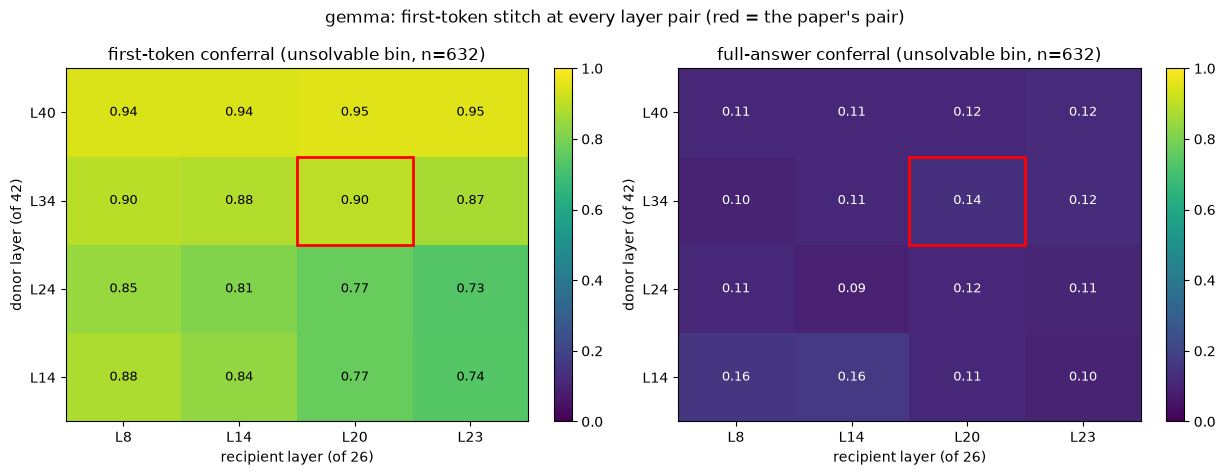

  [plot saved reviewer_checks_gemma_plots/R4_layer_grid.png]
  [2380s]
  [saved reviewer_checks_gemma.json after R4]


In [14]:
# === CELL R4: reviewer Q2 / W3 — every donor layer x recipient layer pair in the grid ===
# For each pair: a first-token task map (the paper's recipe), scored on the paper's unsolvable bin (which does not
# depend on the layers) for first-token and full-answer conferral; the pair's alignment (recon) map; the task map
# fed a shuffled donor state; and a CONST null per recipient layer. The paper's pair reuses R1's map.
t0 = time.time(); R4 = {"donor_layers": GRID_D, "recipient_layers": GRID_R, "paper_pair": [L_D, L_R], "cells": {}}
RESULTS["R4_layer_grid"] = R4
if RUN_GRID:
    B = unsolv_ft; items_B = [ft_ev[i] for i in B]; probs_B = [evalp[i] for i in B]
    _p = np.random.default_rng(2).permutation(len(B)); SH_G = torch.as_tensor(np.roll(_p, 1)[np.argsort(_p)])
    _keep_t, _B_t = torch.as_tensor(_keep_ev), torch.as_tensor(B)
    def _gfirst(M, X): return [t == it["tgt"] for t, it in zip(score(lambda x: apply_map(M, x), items_B, X), items_B)]
    _LR0, _LD0 = L_R, L_D
    try:
        for lr in GRID_R:
            L_R, L_D = lr, _LD0; X2_l = XR_tr[lr]
            Mc = train_map(f"G_CONST_R{lr}", "const", ft_tr, X9T_FT, X2_l)
            const1 = _gfirst(Mc, X9E_FT[_B_t]); R4["cells"][f"CONST R{lr}"] = {"first": R(const1)}
            for ld in GRID_D:
                L_D = ld
                XB = XD_ev[ld][_keep_t][_B_t]
                M = (MAPS["FT"]["task_s0"][0] if (ld, lr) == (_LD0, _LR0)
                     else train_map(f"G_D{ld}_R{lr}", "linear", ft_tr, XD_tr[ld], X2_l, seed=0))
                Mr = dict(W=M["W0"], b=X2_l.float().mean(0).to(DEVICE), mu=M["mu"], W1=None)
                f1, r1, s1 = _gfirst(M, XB), _gfirst(Mr, XB), _gfirst(M, XB[SH_G])
                e = {"first": R(f1), "recon_first": R(r1), "shuffled_first": R(s1), "CONST_first": rate(const1),
                     "first_minus_CONST": paired(const1, f1), "first_minus_shuffled": paired(s1, f1)}
                if GRID_FULL_ANSWER:
                    fF = _ok(gen_pred(model_r, lr, probs_B, vecs=apply_map(M, XB).cpu()), probs_B)
                    e.update(full=R(fF), full_over_first=(round(rate(fF) / rate(f1), 4) if rate(f1) else None))
                R4["cells"][f"D{ld} R{lr}"] = e
                print(f"   donor L{ld:<2d} -> recipient L{lr:<2d}: first {e['first']['ci']}" +
                      (f" | full {e['full']['ci']}" if GRID_FULL_ANSWER else "") +
                      f" | recon first {e['recon_first']['rate']} | shuffled {e['shuffled_first']['rate']} | CONST {rate(const1)}"
                      f"{'   <- the paper' if (ld, lr) == (_LD0, _LR0) else ''}  [{time.time()-t0:.0f}s]")
            save(f"R4 recipient layer {lr}")
    finally:
        L_R, L_D = _LR0, _LD0
    native_full = P0["native_full_unsolv"]["rate"]
    print(f"\n  native full answer on the bin (any layer): {native_full}")
    for key, lab in (("first", "FIRST-TOKEN conferral"), ("full", "FULL-ANSWER conferral")):
        if key == "full" and not GRID_FULL_ANSWER: continue
        print(f"\n  {lab} (rows: donor layer, columns: recipient layer)\n           " + "".join(f"  R{lr:<5d}" for lr in GRID_R))
        for ld in GRID_D:
            print(f"   D{ld:<5d} " + "".join(f"  {R4['cells'][f'D{ld} R{lr}'][key]['rate']:.3f} " for lr in GRID_R))
    ncols = 2 if GRID_FULL_ANSWER else 1
    fig, ax = plt.subplots(1, ncols, figsize=(6.2 * ncols, 4.8), squeeze=False)
    for j, (key, lab) in enumerate((("first", "first-token conferral"), ("full", "full-answer conferral"))[:ncols]):
        Mx = np.array([[R4["cells"][f"D{ld} R{lr}"][key]["rate"] for lr in GRID_R] for ld in GRID_D])
        im = ax[0, j].imshow(Mx, vmin=0, vmax=1, cmap="viridis", origin="lower", aspect="auto")
        for a_ in range(len(GRID_D)):
            for b_ in range(len(GRID_R)):
                ax[0, j].text(b_, a_, f"{Mx[a_, b_]:.2f}", ha="center", va="center", fontsize=9,
                              color="white" if Mx[a_, b_] < 0.5 else "black")
        ax[0, j].add_patch(plt.Rectangle((GRID_R.index(L_R) - 0.5, GRID_D.index(L_D) - 0.5), 1, 1, fill=False, ec="red", lw=2))
        ax[0, j].set_xticks(range(len(GRID_R))); ax[0, j].set_xticklabels([f"L{x}" for x in GRID_R])
        ax[0, j].set_yticks(range(len(GRID_D))); ax[0, j].set_yticklabels([f"L{x}" for x in GRID_D])
        ax[0, j].set_xlabel(f"recipient layer (of {NL_R})"); ax[0, j].set_ylabel(f"donor layer (of {NL_D})")
        ax[0, j].set_title(f"{lab} (unsolvable bin, n={len(B)})"); fig.colorbar(im, ax=ax[0, j], fraction=0.046)
    fig.suptitle(f"{PAIR}: first-token stitch at every layer pair (red = the paper's pair)")
    fig.tight_layout(); _pth = os.path.join(PLOT_DIR, "R4_layer_grid.png"); fig.savefig(_pth, dpi=130); plt.show(); plt.close(fig)
    print(f"  [plot saved {_pth}]")
print(f"  [{time.time()-t0:.0f}s]"); save("R4")

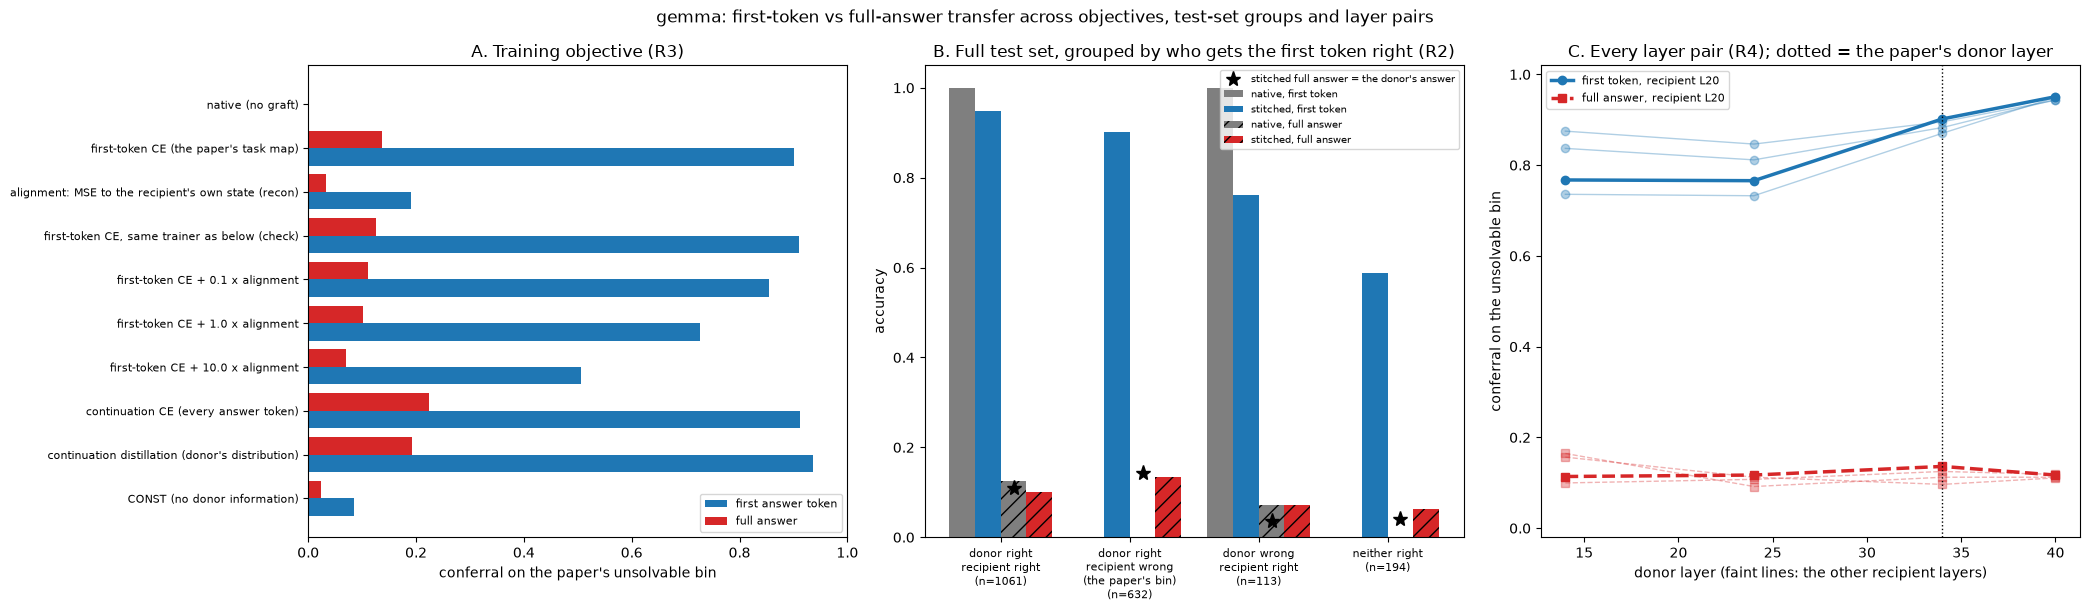

  [plot saved reviewer_checks_gemma_plots/R5_summary.png]

  objectives (first / full on the unsolvable bin):
     native (no graft): (0.0, 0.0)
     first-token CE (the paper's task map): (0.9019, 0.1361)
     alignment: MSE to the recipient's own state (recon): (0.1899, 0.0332)
     first-token CE, same trainer as below (check): (0.9098, 0.125)
     first-token CE + 0.1 x alignment: (0.8544, 0.1108)
     first-token CE + 1.0 x alignment: (0.7263, 0.1013)
     first-token CE + 10.0 x alignment: (0.5063, 0.0696)
     continuation CE (every answer token): (0.913, 0.2231)
     continuation distillation (donor's distribution): (0.9367, 0.193)
     CONST (no donor information): (0.0854, 0.0237)

  full test set, task map (first / full), by first-token group:
     donor right, recipient right: {'native': (1.0, 0.1244), 'stitched': (0.9482, 0.1018), 'stitched_full_equals_donor': 0.1103, 'lost_first': 55, 'lost_full': 63}
     donor right, recipient wrong (= the paper's bin): {'native': (0.0,

In [15]:
# === CELL R5: reviewer Q4 — the key results side by side (one figure) ===
_have2, _have3, _have4 = bool(R2), bool(R3), bool(R4.get("cells"))
fig, ax = plt.subplots(1, 3, figsize=(21, 6.2))
if _have3:
    labs = [l for l in R3 if isinstance(R3[l], dict) and "first" in R3[l]]
    y = np.arange(len(labs))
    ax[0].barh(y + 0.2, [R3[l]["first"]["rate"] for l in labs], 0.4, color="#1f77b4", label="first answer token")
    ax[0].barh(y - 0.2, [R3[l]["full"]["rate"] for l in labs], 0.4, color="#d62728", label="full answer")
    ax[0].set_yticks(y); ax[0].set_yticklabels(labs, fontsize=8); ax[0].invert_yaxis(); ax[0].set_xlim(0, 1)
    ax[0].set_xlabel("conferral on the paper's unsolvable bin"); ax[0].legend(fontsize=8, loc="lower right")
    ax[0].set_title("A. Training objective (R3)")
if _have2:
    part = R2["by first answer token"]; cats = list(part)
    conds = ["native (no graft)", "task map"]; x = np.arange(len(cats)); wd = 0.2
    for j, (c, met, col, hatch) in enumerate([(conds[0], "first", "#7f7f7f", ""), (conds[1], "first", "#1f77b4", ""),
                                              (conds[0], "full", "#7f7f7f", "//"), (conds[1], "full", "#d62728", "//")]):
        ax[1].bar(x + (j - 1.5) * wd, [(part[k].get(c, {}).get(met) or {}).get("rate") or 0 for k in cats], wd, color=col, hatch=hatch,
                  label=f"{'native' if c == conds[0] else 'stitched'}, {'first token' if met == 'first' else 'full answer'}")
    ax[1].plot(x + 0.5 * wd, [part[k].get("task map", {}).get("full_same_as_donor") or 0 for k in cats], "k*", ms=11,
               label="stitched full answer = the donor's answer")
    _short = {cats[0]: "donor right\nrecipient right", cats[1]: "donor right\nrecipient wrong\n(the paper's bin)",
              cats[2]: "donor wrong\nrecipient right", cats[3]: "neither right"}
    ax[1].set_xticks(x); ax[1].set_xticklabels([f"{_short[k]}\n(n={part[k]['n']})" for k in cats], fontsize=8)
    ax[1].set_ylim(0, 1.05); ax[1].set_ylabel("accuracy"); ax[1].legend(fontsize=7, loc="upper right")
    ax[1].set_title("B. Full test set, grouped by who gets the first token right (R2)")
if _have4 and GRID_FULL_ANSWER:
    for key, mk, col in (("first", "o-", "#1f77b4"), ("full", "s--", "#d62728")):
        for lr in GRID_R:
            ax[2].plot(GRID_D, [R4["cells"][f"D{ld} R{lr}"][key]["rate"] for ld in GRID_D], mk, color=col,
                       alpha=0.35 + 0.65 * (lr == L_R), lw=2.5 if lr == L_R else 1,
                       label=(f"{'first token' if key == 'first' else 'full answer'}, recipient L{lr}" if lr == L_R else None))
    ax[2].axvline(L_D, c="k", ls=":", lw=1); ax[2].set_ylim(-0.02, 1.02)
    ax[2].set_xlabel("donor layer (faint lines: the other recipient layers)"); ax[2].set_ylabel("conferral on the unsolvable bin")
    ax[2].legend(fontsize=8); ax[2].set_title("C. Every layer pair (R4); dotted = the paper's donor layer")
fig.suptitle(f"{PAIR}: first-token vs full-answer transfer across objectives, test-set groups and layer pairs")
fig.tight_layout(); _pth = os.path.join(PLOT_DIR, "R5_summary.png"); fig.savefig(_pth, dpi=130); plt.show(); plt.close(fig)
print(f"  [plot saved {_pth}]")
SUM = {}
if _have3:
    SUM["objectives (first / full on the unsolvable bin)"] = {l: (R3[l]["first"]["rate"], R3[l]["full"]["rate"]) for l in R3
                                                             if isinstance(R3[l], dict) and "first" in R3[l]}
if _have2:
    SUM["full test set, task map (first / full), by first-token group"] = {
        k: dict(native=(v["native (no graft)"]["first"]["rate"], v["native (no graft)"]["full"]["rate"]),
                stitched=(v["task map"]["first"]["rate"], v["task map"]["full"]["rate"]),
                stitched_full_equals_donor=v["task map"]["full_same_as_donor"],
                lost_first=v["task map"]["first_lost"], lost_full=v["task map"]["full_lost"])
        for k, v in R2["by first answer token"].items() if v["n"]}
if _have4:
    SUM["layer grid (first / full)"] = {k: (v["first"]["rate"], v.get("full", {}).get("rate")) for k, v in R4["cells"].items()
                                       if not k.startswith("CONST")}
RESULTS["SUMMARY"] = SUM
for k, v in SUM.items():
    print(f"\n  {k}:")
    for a, b in v.items(): print(f"     {a}: {b}")
print("\nSANITY:", {k: v["status"] for k, v in SANITY.items()})
save("R5")